# Solar filaments: complete Kaggle training and submission notebook

**This one notebook contains the complete pipeline.** Its only attached input is
the [competition dataset](https://www.kaggle.com/competitions/filament-segmentation-2026/data).
It installs packages, downloads generic pretrained models, prepares data, trains,
validates and writes **`/kaggle/working/submission.csv`**.

1. Import this `.ipynb` into a new Kaggle notebook.
2. Use **Add Input** to attach the competition data.
3. Set **Accelerator: GPU T4 x2** and **Internet: On**.
4. Run all cells in order. Full training is the default.

Models: YOLO11m box proposals plus ResNet34 and EfficientNetV2-S U-Nets learning
native-resolution masks. It uses two GPUs, **four total loader workers**, separate
annotator targets, grouped validation, learned quality and adaptive mask selection.
The 0.50 score is a target; this new pipeline has no established full-run score.

All helper code is visible below. The notebook automatically assembles its own
worker script for multi-GPU subprocesses. No repository, local Python module,
results archive, previous submission or manually uploaded checkpoint is required.

In [1]:
import importlib.metadata as metadata
import importlib.util
import subprocess
import sys
from pathlib import Path

# Keep Kaggle's installed CUDA torch/torchvision.
requirements = {
    'ultralytics': ('ultralytics', '8.4.198'),
    'segmentation-models-pytorch': ('segmentation-models-pytorch', '0.5.0'),
    'timm': ('timm', '1.0.30'),
    'scikit-learn': ('scikit-learn', '1.9.1'),
}
install = []
for distribution, (package, version) in requirements.items():
    try:
        installed = metadata.version(distribution)
    except metadata.PackageNotFoundError:
        installed = None
    if installed != version:
        install.append(f'{package}=={version}')
for module, package in {
    'pycocotools': 'pycocotools', 'scipy': 'scipy', 'cv2': 'opencv-python-headless',
    'pandas': 'pandas', 'matplotlib': 'matplotlib', 'joblib': 'joblib', 'yaml': 'pyyaml',
}.items():
    if importlib.util.find_spec(module) is None:
        install.append(package)
if install:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', '--no-cache-dir', *install])
print('Packages ready. Use a fresh kernel if you previously imported different versions.')

Packages ready. Use a fresh kernel if you previously imported different versions.


## All helper code

The following cells both define functions for this notebook and capture the exact
same source for GPU workers. Editing and rerunning a helper cell updates its
captured source. Run the worker-assembly cell after all helper cells.

In [2]:
_FILAMENT_SECTIONS = {}

def _filament_section(line, cell):
    name = line.strip()
    if not name or ' ' in name:
        raise ValueError('Give the helper section a single name.')
    compiled = compile(cell, f'<filament:{name}>', 'exec')
    exec(compiled, get_ipython().user_ns)
    _FILAMENT_SECTIONS[name] = cell

get_ipython().register_magic_function(_filament_section, magic_kind='cell', magic_name='filament_section')
print('Inline helper cells enabled.')

Inline helper cells enabled.


### Imports, configuration and mask I/O

In [3]:
%%filament_section imports_and_io
"""Train-only, date-grouped detector + native mask learning for MAGFiLO Kaggle.

All code is included in this Kaggle notebook. No external filament annotations,
precomputed submissions, or test-derived supervision are used.
"""
from __future__ import annotations

import os
for _key in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[_key] = "1"
import argparse
import copy
import csv
import gc
import hashlib
import json
import math
import random
import shutil
import subprocess
import sys
import time
from collections import defaultdict, deque
from concurrent.futures import ThreadPoolExecutor
from contextlib import nullcontext
from datetime import timedelta
from pathlib import Path

import cv2
import numpy as np
import torch
import torch.distributed as dist
from pycocotools import mask as mu
from scipy import ndimage as ndi
from torch import nn
from torch.nn import functional as F
from torch.nn.parallel import DistributedDataParallel as DDP
from torch.utils.data import DataLoader, Dataset, DistributedSampler

cv2.setNumThreads(1)
torch.set_num_threads(1)
SIZE = 2048
VERSION = "kaggle-native-hybrid-v1"
INPUT_ROOT = Path("/kaggle/input")
WORKER_SCRIPT = Path("/kaggle/working/filament_gpu_worker.py")


def default_config():
    return dict(mode="full", data_root="", output_root="/kaggle/working", run_name="kaggle_native_hybrid_v1",
        gpu_ids=[0, 1], cpu_workers=4, seed=20261103, refit_full=True,
        calibration_fraction=.12, report_fraction=.12, minimum_free_gib=2.,
        dense_models=[dict(encoder="resnet34", crop=512),
                      dict(encoder="tu-tf_efficientnetv2_s", crop=768)],
        pretrained=True, dense_epochs=32, dense_steps=288, dense_batch_per_gpu=2,
        dense_lr=3e-4, weight_decay=1e-4, accumulation=3, ema_decay=.995,
        pq_every=4, tile_size=1024, tile_overlap=256, inference_batch=2,
        tta=4, detector_weights="yolo11m.pt", detector_size=2048,
        detector_epochs=45, detector_batch_per_gpu=1, detector_lr=.001,
        detector_conf=.07, max_det=100, max_dense_candidates=512, quality_folds=5,
        pixel_thresholds=[.35, .5, .65], smoke_sources=3)


def save_json(path, data):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temp = path.with_name(path.name + ".tmp")
    temp.write_text(json.dumps(data, indent=2, allow_nan=False), encoding="utf8")
    os.replace(temp, path)


def load_json(path):
    return json.loads(Path(path).read_text(encoding="utf8"))


def digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True).encode()).hexdigest()


def file_sha(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()


def bounded_map(fn, items, workers=4):
    """At most four active/pending native images; never queue the entire dataset."""
    items = iter(items)
    with ThreadPoolExecutor(max_workers=workers) as pool:
        pending = deque()
        for _ in range(workers):
            item = next(items, None)
            if item is not None:
                pending.append(pool.submit(fn, item))
        while pending:
            yield pending.popleft().result()
            item = next(items, None)
            if item is not None:
                pending.append(pool.submit(fn, item))


def encode(mask):
    rle = mu.encode(np.asfortranarray(mask, dtype=np.uint8))
    return dict(size=[int(x) for x in rle["size"]], counts=rle["counts"].decode("ascii"))


def decode(rle):
    rle = dict(rle)
    if isinstance(rle["counts"], str):
        rle["counts"] = rle["counts"].encode("ascii")
    return mu.decode(rle).astype(bool)


def annotation_rle(ann, shape=(SIZE, SIZE)):
    seg = ann["segmentation"]
    if isinstance(seg, list):
        r = mu.merge(mu.frPyObjects(seg, *shape))
    elif isinstance(seg["counts"], list):
        r = mu.frPyObjects(seg, *shape)
    else:
        r = dict(seg)
        if isinstance(r["counts"], str):
            r["counts"] = r["counts"].encode("ascii")
    return dict(size=list(shape), counts=r["counts"].decode("ascii"))


def read_gray(path):
    image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if image is None or image.shape != (SIZE, SIZE):
        raise ValueError(f"Expected a readable native {SIZE}x{SIZE} image: {path}")
    return image

### Solar normalization and Kaggle data preparation

In [4]:
%%filament_section data
def normalize_solar(gray):
    """Always normalize. Uncertain geometry disables radial correction only.

    Three uint8 channels: global standardization, bounded radial correction,
    CLAHE of the corrected view. No hard limb clipping or morphology inpainting.
    """
    if gray.ndim != 2 or gray.dtype != np.uint8:
        raise ValueError("uint8 grayscale required")
    h, w = gray.shape
    small = cv2.resize(gray, (256, 256), interpolation=cv2.INTER_AREA)
    threshold, binary = cv2.threshold(small, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    good, cx, cy, radius = False, w / 2, h / 2, .45 * min(h, w)
    if contours:
        contour = max(contours, key=cv2.contourArea)
        if len(contour) >= 5:
            (x, y), (a, b), _ = cv2.fitEllipse(contour)
            good = (100 < x < 156 and 100 < y < 156 and 180 < min(a, b) < 253
                    and max(a, b) / max(min(a, b), 1) < 1.13)
            if good:
                cx, cy = x * w / 256, y * h / 256
                radius = (a + b) * min(h, w) / (4 * 256)
    yy, xx = np.ogrid[:h, :w]
    rr = np.sqrt(((xx - cx) / radius)**2 + ((yy - cy) / radius)**2)
    support = (rr < .88) & (gray > max(5, threshold * .35))
    if support.sum() < h * w * .1:
        support = (rr < .75)
    values = gray[support].astype(np.float32)
    mean, std = float(values.mean()), max(float(values.std()), 8.)
    raw = np.clip(128 + 32 * (gray.astype(np.float32) - mean) / std, 0, 255)
    corrected = gray.astype(np.float32)
    if good:
        # Statistics are estimated at 256² to avoid repeated full-disk sorting.
        sr = cv2.resize(rr.astype(np.float32), (256, 256), interpolation=cv2.INTER_AREA)
        bins = np.minimum((sr * 48).astype(int), 63)
        profile = np.array([np.median(small[(bins == k) & (small > 5)])
                            if np.any((bins == k) & (small > 5)) else np.nan for k in range(48)])
        valid = np.flatnonzero(np.isfinite(profile))
        if len(valid) > 24:
            profile = np.interp(np.arange(48), valid, profile[valid])
            profile = ndi.gaussian_filter1d(profile, 2)
            reference = float(np.median(profile[5:35]))
            gain = np.clip(reference / np.maximum(profile, 20), .75, 1.35)
            correction = np.interp(np.minimum(rr, 47 / 48) * 48, np.arange(48), gain)
            corrected *= correction.astype(np.float32)
    cvalues = corrected[support]
    corrected = np.clip(128 + 32 * (corrected - float(cvalues.mean())) /
                        max(float(cvalues.std()), 8.), 0, 255).astype(np.uint8)
    clahe = cv2.createCLAHE(clipLimit=1.5, tileGridSize=(16, 16)).apply(corrected)
    return np.stack([raw.astype(np.uint8), corrected, clahe], -1), dict(
        geometry_ok=bool(good), mean=mean, std=std)


def discover_root(configured=""):
    """Read the attached competition data exclusively under /kaggle/input."""
    input_root = INPUT_ROOT.resolve()
    name = "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
    if not input_root.is_dir():
        raise FileNotFoundError("/kaggle/input is missing. Run this notebook on Kaggle and attach the competition data.")
    if configured:
        candidates = [Path(configured).resolve()]
        if not candidates[0].is_relative_to(input_root):
            raise ValueError("DATA_ROOT_OVERRIDE must point inside /kaggle/input.")
    else:
        candidates = sorted({p.parent.parent for p in input_root.rglob(name)})
    matches = [root for root in candidates if
               (root / "train" / name).is_file() and
               (root / "train" / "train_images").is_dir() and
               (root / "test" / "test_images").is_dir()]
    if len(matches) == 1:
        return matches[0].resolve()
    if len(matches) > 1:
        raise ValueError("Multiple competition copies found. Set DATA_ROOT_OVERRIDE to one of: " +
                         ", ".join(map(str, matches)))
    raise FileNotFoundError("Attach the filament-segmentation-2026 competition dataset using Add Input. "
                            "Expected its train annotation JSON, train/train_images and test/test_images.")


def index_data(root, cfg):
    path = root / "train" / "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
    data = load_json(path)
    annotations = defaultdict(list)
    for a in data["annotations"]:
        annotations[a["image_id"]].append(a)
    by_name = defaultdict(list)
    for row in data["images"]:
        assert (row["height"], row["width"]) == (SIZE, SIZE)
        rles = [annotation_rle(a) for a in annotations[row["id"]]]
        boxes = [list(map(float, mu.toBbox({**r, "counts": r["counts"].encode()}))) for r in rles]
        by_name[Path(row["file_name"]).name].append(dict(id=row["id"], rles=rles, boxes=boxes))
    sources = [dict(name=n, stem=Path(n).stem, date=Path(n).stem[:8], views=v,
                    image=str(root / "train" / "train_images" / n)) for n, v in sorted(by_name.items())]
    dates = np.array(sorted({s["date"] for s in sources}))
    np.random.default_rng(cfg["seed"]).shuffle(dates)
    nr = max(1, round(len(dates) * cfg["report_fraction"]))
    nc = max(1, round(len(dates) * cfg["calibration_fraction"]))
    report, calibration = set(dates[:nr]), set(dates[nr:nr + nc])
    splits = {"train": [], "calibration": [], "report": []}
    for source in sources:
        key = "report" if source["date"] in report else "calibration" if source["date"] in calibration else "train"
        splits[key].append(source)
    tests = [dict(name=p.name, stem=p.stem, date=p.stem[:8], image=str(p), views=[])
             for p in sorted((root / "test" / "test_images").glob("*"))
             if p.suffix.lower() in (".jpg", ".jpeg", ".png")]
    if {s["stem"] for s in sources} & {s["stem"] for s in tests}:
        raise ValueError("Train/test filenames overlap.")
    if cfg["mode"] == "smoke":
        splits = {k: v[:cfg["smoke_sources"]] for k, v in splits.items()}
        tests = tests[:cfg["smoke_sources"]]
    splits["test"] = tests
    assert not (set(s["date"] for s in splits["train"]) &
                set(s["date"] for k in ("calibration", "report") for s in splits[k]))
    return splits, file_sha(path)


def prepare(cfg):
    cfg = copy.deepcopy(cfg)
    for computed in ("run", "fingerprint", "annotation_sha", "runtime_sha"):
        cfg.pop(computed, None)
    if cfg["cpu_workers"] != 4:
        raise ValueError("This run reserves exactly four CPU workers in total.")
    if cfg["mode"] not in ("full", "smoke"):
        raise ValueError("mode must be full or smoke")
    if cfg["mode"] == "smoke":
        cfg.update(dense_epochs=1, dense_steps=2, pq_every=1, detector_epochs=1,
                   detector_size=512, tta=1, refit_full=False, tile_size=512,
                   tile_overlap=64, dense_batch_per_gpu=1, accumulation=1,
                   max_dense_candidates=32, pixel_thresholds=[.5])
        cfg["dense_models"] = [dict(encoder="resnet18", crop=256)]
        cfg["detector_weights"] = "yolo11n.pt"
    root = discover_root(cfg["data_root"])
    cfg["data_root"] = str(root)
    cfg["output_root"] = str(Path(cfg["output_root"]).resolve())
    splits, annotation_sha = index_data(root, cfg)
    image_hashes = dict(bounded_map(lambda s: (s["stem"], file_sha(s["image"])),
        [s for rows in splits.values() for s in rows], cfg["cpu_workers"]))
    runtime_sha = file_sha(WORKER_SCRIPT)
    fingerprint = digest(dict(version=VERSION, cfg=cfg, annotations=annotation_sha,
                              sources={k: [s["name"] for s in v] for k, v in splits.items()},
                              images=image_hashes, runtime=runtime_sha))
    run = Path(cfg["output_root"]).resolve() / (cfg["run_name"] + "_" + fingerprint[:10])
    run.mkdir(parents=True, exist_ok=True)
    cfg.update(run=str(run), fingerprint=fingerprint, annotation_sha=annotation_sha, runtime_sha=runtime_sha)
    all_sources = [s for rows in splits.values() for s in rows]
    # Measure actual compressed cache size, rather than budgeting multiple RGB copies.
    cache = run / "cache"
    cache.mkdir(exist_ok=True)
    sample_sizes = []
    for s in all_sources[:min(4, len(all_sources))]:
        feature, _ = normalize_solar(read_gray(s["image"]))
        ok, png = cv2.imencode(".png", feature, [cv2.IMWRITE_PNG_COMPRESSION, 3])
        if not ok:
            raise OSError("PNG encoder failed")
        sample_sizes.append(len(png))
    # Only missing files need disk headroom on rerun. Targets are small bit-packed PNGs.
    missing = sum(not (cache / (s["stem"] + ".png")).exists() for s in all_sources)
    estimated = (max(sample_sizes) * missing * 1.35 + 200_000 *
                 sum(len(s["views"]) for s in all_sources)) / 2**30
    free = shutil.disk_usage(run).free / 2**30
    required = estimated + 3.5 + cfg["minimum_free_gib"]
    print(f"Disk free {free:.1f} GiB; estimated new cache {estimated:.1f}, models/maps 3.5, "
          f"reserve {cfg['minimum_free_gib']:.1f}. No Ultralytics disk cache or duplicated images.", flush=True)
    if free < required:
        raise OSError(f"Estimated incremental need {required:.1f} GiB, free {free:.1f}. "
                      "Choose an output disk with more room; no dataset is deleted automatically.")

    def process(s):
        s = copy.deepcopy(s)
        s["image_sha"] = image_hashes[s["stem"]]
        target = cache / (s["stem"] + ".png")
        meta_path = cache / (s["stem"] + ".json")
        if not target.is_file() or not meta_path.is_file():
            image, meta = normalize_solar(read_gray(s["image"]))
            if not cv2.imwrite(str(target), image, [cv2.IMWRITE_PNG_COMPRESSION, 3]):
                raise OSError(target)
            save_json(meta_path, meta)
        s.update(cache=str(target), photometry=load_json(meta_path))
        for view in s["views"]:
            packed_path = cache / (view["id"] + "_target.png")
            if not packed_path.is_file():
                fg, edges = np.zeros((SIZE, SIZE), np.uint8), np.zeros((SIZE, SIZE), np.uint8)
                for rle in view["rles"]:
                    mask = decode(rle).astype(np.uint8)
                    fg |= mask
                    edges |= cv2.morphologyEx(mask, cv2.MORPH_GRADIENT, np.ones((3, 3), np.uint8))
                if not cv2.imwrite(str(packed_path), fg + 2 * edges):
                    raise OSError(packed_path)
            view["target"] = str(packed_path)
        return s

    for name, sources in splits.items():
        splits[name] = list(bounded_map(process, sources, cfg["cpu_workers"]))
        print(f"Prepared {name}: {len(sources)} physical images, "
              f"{sum(len(s['views']) for s in sources)} annotator records", flush=True)
    import importlib.metadata as metadata
    packages = {name: metadata.version(name) for name in
                ("torch", "torchvision", "ultralytics", "segmentation-models-pytorch", "timm", "scikit-learn", "pycocotools")}
    manifest = dict(config=cfg, splits=splits, packages=packages, python=sys.version)
    save_json(run / "manifest.json", manifest)
    save_json(run / "config.json", cfg)
    prepare_detector(manifest)
    return cfg, manifest


def prepare_detector(manifest):
    """Original per-annotator boxes; hard-link images so records cost no RGB copies."""
    cfg, splits = manifest["config"], manifest["splits"]
    root = Path(cfg["run"]) / "detector_data"
    for part in ("train", "calibration", "report"):
        (root / "images" / part).mkdir(parents=True, exist_ok=True)
        (root / "labels" / part).mkdir(parents=True, exist_ok=True)
        for source in splits[part]:
            for view in source["views"]:
                target = root / "images" / part / (view["id"] + ".png")
                if not target.exists():
                    try:
                        os.link(source["cache"], target)
                    except OSError:
                        # Same output filesystem normally supports hardlinks. Do not silently copy GBs.
                        os.symlink(source["cache"], target)
                lines = []
                for x, y, w, h in view["boxes"]:
                    lines.append(f"0 {(x + w/2)/SIZE:.9f} {(y + h/2)/SIZE:.9f} {w/SIZE:.9f} {h/SIZE:.9f}")
                (root / "labels" / part / (view["id"] + ".txt")).write_text("\n".join(lines), encoding="utf8")
    train_files = sorted((root / "images" / "train").glob("*.png"))
    all_files = train_files + sorted((root / "images" / "calibration").glob("*.png")) + sorted((root / "images" / "report").glob("*.png"))
    for name, files in (("all", all_files), ("train", train_files)):
        (root / (name + ".txt")).write_text("\n".join(str(p.absolute()) for p in files), encoding="utf8")
    for full in (False, True):
        data = dict(path=str(root), train=str(root / ("all.txt" if full else "train.txt")),
                    val=str(root / "images" / ("train" if full else "calibration")), names={0: "filament"})
        import yaml
        (root / ("full.yaml" if full else "selection.yaml")).write_text(yaml.safe_dump(data), encoding="utf8")

### Native mask models, crops and losses

In [5]:
%%filament_section models
def device_setup(cfg, distributed=False):
    if not torch.cuda.is_available():
        raise RuntimeError("CUDA is required for training. Use Kaggle GPU T4 x2.")
    local = int(os.environ.get("LOCAL_RANK", 0))
    gpu = cfg["gpu_ids"][local]
    torch.cuda.set_device(gpu)
    if distributed and len(cfg["gpu_ids"]) > 1:
        dist.init_process_group("gloo" if os.name == "nt" else "nccl", timeout=timedelta(minutes=45))
    return torch.device(f"cuda:{gpu}"), local, len(cfg["gpu_ids"])


def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def build_dense(spec, pretrained=False):
    import segmentation_models_pytorch as smp
    model = smp.Unet(encoder_name=spec["encoder"], encoder_weights="imagenet" if pretrained else None,
        in_channels=3, classes=2, decoder_channels=(128, 64, 32, 16, 16), decoder_attention_type="scse")
    # Stable statistics at small per-GPU batch. Encoder ImageNet BN statistics stay frozen.
    def replace_bn(module):
        for name, child in list(module.named_children()):
            if isinstance(child, nn.BatchNorm2d):
                setattr(module, name, nn.GroupNorm(math.gcd(8, child.num_features), child.num_features))
            else:
                replace_bn(child)
    replace_bn(model.decoder)
    # SMP's last decoder block has no skip input, so attention1 is never called.
    # Exclude those six dormant SCSE parameters from DDP gradient reduction.
    model.decoder.blocks[-1].attention1.requires_grad_(False)
    return model


def train_mode(model):
    model.train()
    for child in model.encoder.modules():
        if isinstance(child, nn.modules.batchnorm._BatchNorm):
            child.eval()


class CropDataset(Dataset):
    def __init__(self, sources, crop, length, seed):
        self.sources, self.crop, self.length, self.seed, self.epoch = sources, crop, length, seed, 0
        self.cache = {}  # Each loader worker retains only its last physical image.

    def __len__(self):
        return self.length

    def __getitem__(self, index):
        rng = np.random.default_rng(self.seed + self.epoch * 10_000_019 + int(index))
        s = self.sources[int(rng.integers(len(self.sources)))]
        view = s["views"][int(rng.integers(len(s["views"])))]
        key = view["id"]
        if key not in self.cache:
            self.cache.clear()
            self.cache[key] = (cv2.imread(s["cache"]), cv2.imread(view["target"], 0))
        image, packed = self.cache[key]
        size = self.crop
        choice = rng.random()
        if choice < .65 and view["boxes"]:
            boxes = np.array(view["boxes"])
            weights = np.maximum(boxes[:, 2] * boxes[:, 3], 50)**(-.3)
            x, y, w, h = boxes[rng.choice(len(boxes), p=weights / weights.sum())]
            cx, cy = x + rng.random() * w, y + rng.random() * h
            x0 = round(cx - size * rng.uniform(.25, .75))
            y0 = round(cy - size * rng.uniform(.25, .75))
        elif choice < .85:
            # Genuine dark-region backgrounds, including sunspots and imperfect disks.
            points = rng.integers(150, SIZE - 150, size=(24, 2))
            j = np.argmin(image[points[:, 0], points[:, 1], 1])
            y0, x0 = points[j] - size // 2
        else:
            x0, y0 = rng.integers(0, SIZE - size + 1, size=2)
        x0, y0 = int(np.clip(x0, 0, SIZE - size)), int(np.clip(y0, 0, SIZE - size))
        x = image[y0:y0 + size, x0:x0 + size].copy()
        p = packed[y0:y0 + size, x0:x0 + size]
        y = np.stack([(p & 1) > 0, (p & 2) > 0], -1).astype(np.float32)
        k = int(rng.integers(4))
        x, y = np.rot90(x, k), np.rot90(y, k)
        if rng.random() < .5:
            x, y = x[:, ::-1], y[:, ::-1]
        x = x.astype(np.float32) / 255
        x = np.clip((x - .5) * rng.uniform(.8, 1.2) + .5 + rng.uniform(-.06, .06), 0, 1)
        x = (x - np.array([.485, .456, .406], np.float32)) / np.array([.229, .224, .225], np.float32)
        return torch.from_numpy(np.ascontiguousarray(x.transpose(2, 0, 1))), torch.from_numpy(np.ascontiguousarray(y.transpose(2, 0, 1)))


def dense_loss(logits, targets):
    with torch.autocast(device_type=logits.device.type, enabled=False):
        logits, targets = logits.float(), targets.float()
        p = logits.sigmoid()
        fg, edge = targets[:, :1], targets[:, 1:2]
        # Local contour errors receive extra weight without inflating every positive pixel.
        weights = 1 + 3 * edge
        bce = (F.binary_cross_entropy_with_logits(logits[:, :1], fg, reduction="none") * weights).mean()
        dims = (1, 2, 3)
        dice = 1 - ((2 * (p[:, :1] * fg).sum(dims) + 1) /
                    (p[:, :1].sum(dims) + fg.sum(dims) + 1)).mean()
        edge_bce = F.binary_cross_entropy_with_logits(logits[:, 1:2], edge, pos_weight=logits.new_tensor(3.))
        return .45 * bce + .45 * dice + .1 * edge_bce

### Native prediction and official PQ scoring

In [6]:
%%filament_section metrics
def update_ema(ema, model, decay):
    with torch.no_grad():
        for dst, src in zip(ema.parameters(), model.parameters()):
            dst.lerp_(src.detach(), 1 - decay)
        for dst, src in zip(ema.buffers(), model.buffers()):
            dst.copy_(src.detach())


def tile_starts(size, tile, overlap):
    if tile >= size:
        return [0]
    return sorted(set([*range(0, size - tile + 1, tile - overlap), size - tile]))


@torch.inference_mode()
def dense_predict(model, image, device, tile=1024, overlap=256, batch=2, tta=4):
    h, w = image.shape[:2]
    tile = min(tile, h, w)
    if tile % 32 or not 0 <= overlap < tile or tta not in (1, 4, 8):
        raise ValueError("Tiles must be divisible by 32; 0 <= overlap < tile; TTA = 1/4/8")
    positions = [(y, x) for y in tile_starts(h, tile, overlap) for x in tile_starts(w, tile, overlap)]
    hann = np.maximum(np.outer(np.hanning(tile), np.hanning(tile)), .02).astype(np.float32)
    total, weight = np.zeros((2, h, w), np.float32), np.zeros((h, w), np.float32)
    model.eval()
    for start in range(0, len(positions), batch):
        pos = positions[start:start + batch]
        values = np.stack([image[y:y + tile, x:x + tile] for y, x in pos]).astype(np.float32) / 255
        values = (values - np.array([.485, .456, .406])) / np.array([.229, .224, .225])
        inp = torch.from_numpy(values.transpose(0, 3, 1, 2).copy()).to(device, dtype=torch.float32)
        probabilities = torch.zeros((len(pos), 2, tile, tile), device=device, dtype=torch.float32)
        for t in range(tta):
            dims = [] if t % 4 == 0 else [-1] if t % 4 == 1 else [-2] if t % 4 == 2 else [-2, -1]
            z = inp.transpose(-1, -2) if t >= 4 else inp
            z = z.flip(dims) if dims else z
            with torch.autocast(device_type=device.type, enabled=device.type == "cuda"):
                p = model(z).float().sigmoid()
            p = p.flip(dims) if dims else p
            p = p.transpose(-1, -2) if t >= 4 else p
            probabilities.add_(p, alpha=1 / tta)
        arrays = probabilities.cpu().numpy()
        for (y, x), p in zip(pos, arrays):
            total[:, y:y + tile, x:x + tile] += p * hann
            weight[y:y + tile, x:x + tile] += hann
    return total / np.maximum(weight, 1e-6)


def metric_counts(gt, predicted):
    if gt and predicted:
        a = [{**r, "counts": r["counts"].encode()} for r in gt]
        b = [{**r, "counts": r["counts"].encode()} for r in predicted]
        iou = np.asarray(mu.iou(a, b, [0] * len(b)))
    else:
        iou = np.zeros((len(gt), len(predicted)))
    hit = iou > .5
    return np.array([iou[hit].sum(), hit.sum(), (~hit.any(0)).sum(), (~hit.any(1)).sum()], np.float64)


def summarize(counts):
    iou, tp, fp, fn = map(float, counts)
    denominator = tp + .5 * (fp + fn)
    return dict(PQ=iou / denominator if denominator else 0., SQ=iou / tp if tp else 0.,
                RQ=tp / denominator if denominator else 0., TP=int(tp), FP=int(fp), FN=int(fn), sum_IoU=iou)


def components(prob, threshold=.5, minimum=20, maximum=None):
    n, labels, stats, _ = cv2.connectedComponentsWithStats((prob >= threshold).astype(np.uint8), 8)
    ids = np.flatnonzero(stats[1:, cv2.CC_STAT_AREA] >= minimum) + 1
    if maximum is not None and len(ids) > maximum:
        sums = np.bincount(labels.ravel(), weights=prob.ravel(), minlength=n)
        means = sums[ids] / stats[ids, cv2.CC_STAT_AREA]
        ids = ids[np.argsort(-means, kind="stable")[:maximum]]
    for k in ids:
        x, y, w, h, area = map(int, stats[k])
        if area >= minimum:
            yield (x, y, x + w, y + h), labels[y:y + h, x:x + w] == k


def full_rle(box, mask, shape=None):
    shape = (SIZE, SIZE) if shape is None else shape
    x0, y0, x1, y1 = box
    if mask.shape != (y1 - y0, x1 - x0):
        raise ValueError("ROI and mask shapes differ")
    if mask.size > shape[0] * shape[1] // 8:
        image = np.zeros(shape, np.uint8)
        image[y0:y1, x0:x1] = mask
        return encode(image)
    # Encode sparse ROIs directly in the GLOBAL column-major index space. Avoid
    # allocating/encoding a 4-million-pixel zero canvas for every tiny candidate.
    cols, rows = np.nonzero(mask.T)
    indices = (cols.astype(np.int64) + x0) * shape[0] + rows + y0
    if not len(indices):
        counts = [shape[0] * shape[1]]
    else:
        breaks = np.flatnonzero(np.diff(indices) != 1)
        starts = indices[np.r_[0, breaks + 1]]
        ends = indices[np.r_[breaks, len(indices) - 1]]
        runs = np.empty(len(starts) * 2, np.int64)
        runs[0::2] = starts - np.r_[-1, ends[:-1]] - 1
        runs[1::2] = ends - starts + 1
        counts = runs.tolist()
        tail = shape[0] * shape[1] - int(ends[-1]) - 1
        if tail:
            counts.append(tail)
    rle = mu.frPyObjects(dict(size=list(shape), counts=counts), *shape)
    return dict(size=list(shape), counts=rle["counts"].decode("ascii"))


def checkpoint_save(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temp = path.with_suffix(".tmp")
    torch.save(value, temp)
    os.replace(temp, path)

### Distributed mask training worker

In [7]:
%%filament_section mask_training
def train_dense(config_path, member, full=False):
    cfg = load_json(config_path)
    manifest = load_json(Path(cfg["run"]) / "manifest.json")
    device, rank, world = device_setup(cfg, distributed=True)
    seed_all(cfg["seed"] + member * 101)
    spec = cfg["dense_models"][member]
    out = Path(cfg["run"]) / ("full_models" if full else "selection_models") / f"dense_{member}"
    out.mkdir(parents=True, exist_ok=True)
    done = out / "complete.json"
    if done.is_file():
        print(f"Already complete: {out}", flush=True)
        if dist.is_initialized(): dist.destroy_process_group()
        return
    epochs = cfg["dense_epochs"]
    if full:
        epochs = load_json(Path(cfg["run"]) / "selection_models" / f"dense_{member}" / "complete.json")["best_epoch"]
    sources = manifest["splits"]["train"]
    if full:
        sources = sources + manifest["splits"]["calibration"] + manifest["splits"]["report"]
    steps = math.ceil(cfg["dense_steps"] * len(sources) / max(len(manifest["splits"]["train"]), 1)) if full else cfg["dense_steps"]
    length = steps * cfg["dense_batch_per_gpu"] * world
    dataset = CropDataset(sources, spec["crop"], length, cfg["seed"] + member * 111)
    sampler = DistributedSampler(dataset, world, rank, shuffle=True, seed=cfg["seed"])
    loader = DataLoader(dataset, batch_size=cfg["dense_batch_per_gpu"], sampler=sampler,
        num_workers=cfg["cpu_workers"] // world, pin_memory=True, persistent_workers=False,
        prefetch_factor=2, drop_last=True)
    # Download the generic ImageNet initializer once before other ranks open it.
    if rank == 0:
        model = build_dense(spec, cfg["pretrained"])
    if dist.is_initialized(): dist.barrier()
    if rank != 0:
        model = build_dense(spec, cfg["pretrained"])
    model = model.to(device)
    ema = copy.deepcopy(model).eval().requires_grad_(False)
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg["dense_lr"], weight_decay=cfg["weight_decay"])
    scaler = torch.amp.GradScaler("cuda")
    begin, best, best_epoch, updates = 0, -1., epochs, 0
    last = out / "last_training.pt"
    if last.is_file():
        state = torch.load(last, map_location="cpu", weights_only=False)
        if state["fingerprint"] != cfg["fingerprint"]:
            raise RuntimeError("Checkpoint configuration mismatch")
        model.load_state_dict(state["model"])
        ema.load_state_dict(state["ema"])
        optimizer.load_state_dict(state["optimizer"])
        scaler.load_state_dict(state["scaler"])
        begin, best, best_epoch, updates = state["epoch"], state["best"], state["best_epoch"], state["updates"]
    wrapped = DDP(model, device_ids=[device.index], broadcast_buffers=False) if world > 1 else model
    if begin == 0:
        ema.load_state_dict(model.state_dict())
    print(f"Dense member {member}, rank {rank}/{world}: {device}, {len(sources)} sources, "
          f"native {spec['crop']} crops, {len(loader)} microbatches/epoch, "
          f"{cfg['cpu_workers']//world} loader workers", flush=True)
    for epoch in range(begin, epochs):
        started = time.time()
        dataset.epoch = epoch
        sampler.set_epoch(epoch)
        train_mode(model)
        total = 0.
        optimizer.zero_grad(set_to_none=True)
        for step, (x, y) in enumerate(loader):
            # Entire planned schedule reaches its low-LR end; no patience truncation.
            fraction = (epoch + step / len(loader)) / max(epochs, 1)
            warm = min(1., (epoch * len(loader) + step + 1) / max(len(loader), 1))
            lr = cfg["dense_lr"] * warm * (.05 + .95 * (1 + math.cos(math.pi * fraction)) / 2)
            for group in optimizer.param_groups: group["lr"] = lr
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            accumulation = cfg["accumulation"]
            last_group = step // accumulation == (len(loader) - 1) // accumulation
            group_size = len(loader) % accumulation if last_group and len(loader) % accumulation else accumulation
            update = (step + 1) % accumulation == 0 or step + 1 == len(loader)
            context = wrapped.no_sync() if world > 1 and not update else nullcontext()
            with context:
                with torch.autocast("cuda"):
                    loss = dense_loss(wrapped(x), y)
                scaler.scale(loss / group_size).backward()
            total += loss.detach().item()
            if update:
                scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_(model.parameters(), 1.)
                previous_scale = scaler.get_scale()
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad(set_to_none=True)
                if scaler.get_scale() >= previous_scale:
                    updates += 1
                    update_ema(ema, model, min(cfg["ema_decay"], (1 + updates) / (10 + updates)))
            if step == 0:
                audit = dict(rank=rank, world_size=world, gpu=str(device), gpu_name=torch.cuda.get_device_name(device),
                    observed_batch=int(x.shape[0]), native_crop=list(x.shape[-2:]),
                    loader_workers=loader.num_workers, total_loader_workers=loader.num_workers * world)
                save_json(out / f"rank_{rank}_resources.json", audit)
                print(json.dumps(audit), flush=True)
            elif (step + 1) % 32 == 0:
                print(f"Dense {member} rank {rank}: epoch {epoch+1}/{epochs}, step {step+1}/{len(loader)}, "
                      f"loss {total/(step+1):.4f}, lr {lr:.6f}", flush=True)
        counts = np.zeros(4, np.float64)
        evaluate = not full and ((epoch + 1) % cfg["pq_every"] == 0 or epoch + 1 == epochs)
        if evaluate:
            for image_index, source in enumerate(manifest["splits"]["calibration"][rank::world]):
                image = cv2.imread(source["cache"])
                p = dense_predict(ema, image, device, cfg["tile_size"], cfg["tile_overlap"], cfg["inference_batch"], 1)[0]
                rles = [full_rle(box, mask) for box, mask in components(p, .5, 100) if p[box[1]:box[3], box[0]:box[2]][mask].max() > .8]
                for view in source["views"]:
                    counts += metric_counts(view["rles"], rles)
                if (image_index + 1) % 10 == 0:
                    print(f"Dense {member} rank {rank}: fixed-rule PQ check, {image_index+1} images", flush=True)
        stats = torch.tensor([total / len(loader), *counts], device=device, dtype=torch.float64)
        if world > 1: dist.all_reduce(stats)
        values = stats.cpu().numpy()
        pq = summarize(values[1:])["PQ"] if evaluate else None
        if evaluate and pq > best:
            best, best_epoch = pq, epoch + 1
            if rank == 0:
                checkpoint_save(out / "best.pt", dict(state=ema.state_dict(), spec=spec, epoch=best_epoch,
                    fingerprint=cfg["fingerprint"], checkpoint_PQ=best))
        if rank == 0:
            checkpoint_save(out / "last.pt", dict(state=ema.state_dict(), spec=spec, epoch=epoch + 1,
                fingerprint=cfg["fingerprint"]))
            checkpoint_save(last, dict(model=model.state_dict(), ema=ema.state_dict(), optimizer=optimizer.state_dict(),
                scaler=scaler.state_dict(), epoch=epoch + 1, best=best, best_epoch=best_epoch,
                updates=updates, fingerprint=cfg["fingerprint"]))
            log = dict(epoch=epoch + 1, loss=float(values[0] / world), fixed_rule_calibration_PQ=pq,
                lr=lr, updates=updates, seconds=round(time.time() - started, 2),
                peak_vram_gib=round(torch.cuda.max_memory_allocated(device) / 2**30, 3))
            with (out / "history.jsonl").open("a", encoding="utf8") as f:
                f.write(json.dumps(log) + "\n")
            print(json.dumps(log), flush=True)
    if rank == 0:
        if full:
            shutil.copy2(out / "last.pt", out / "best.pt")
        save_json(done, dict(best_epoch=best_epoch, fixed_rule_calibration_PQ=best if not full else None,
            epochs=epochs, updates=updates, checkpoint_sha=file_sha(out / "best.pt")))
        # Complete model weights remain; optimizer recovery state no longer needed.
        last.unlink(missing_ok=True)
    if world > 1:
        dist.barrier()
        dist.destroy_process_group()

### Detector training and GPU launchers

In [8]:
%%filament_section detector_training
def train_detector(config_path, full=False):
    from ultralytics import YOLO, settings
    from ultralytics.models.yolo.detect import DetectionTrainer
    from ultralytics.data.build import build_dataloader
    from ultralytics.utils.torch_utils import torch_distributed_zero_first
    cfg = load_json(config_path)
    rank = int(os.environ.get("LOCAL_RANK", 0))
    world = len(cfg["gpu_ids"])
    out = Path(cfg["run"]) / ("full_models" if full else "selection_models") / "detector"
    if (out / "complete.json").is_file():
        print(f"Already complete: {out}", flush=True)
        return
    settings.update({k: False for k in ("wandb", "mlflow", "clearml", "comet", "tensorboard", "raytune") if k in settings})

    class FourWorkerTrainer(DetectionTrainer):
        def get_dataloader(self, dataset_path, batch_size=16, rank=0, mode="train"):
            if mode == "val":
                batch_size = 1
            with torch_distributed_zero_first(rank):
                dataset = self.build_dataset(dataset_path, mode, batch_size)
            return build_dataloader(dataset, batch=batch_size,
                workers=cfg["cpu_workers"] // world if mode == "train" else 0,
                shuffle=mode == "train", rank=rank, drop_last=False, device=self.device)

    epochs = cfg["detector_epochs"]
    if full:
        epochs = load_json(Path(cfg["run"]) / "selection_models" / "detector" / "complete.json")["best_epoch"]
    source = out / "weights" / "last.pt"
    resume = source.is_file()
    model = YOLO(str(source) if resume else cfg["detector_weights"])
    model.train(trainer=FourWorkerTrainer, data=str(Path(cfg["run"]) / "detector_data" /
        ("full.yaml" if full else "selection.yaml")),
        epochs=epochs, patience=0, imgsz=cfg["detector_size"],
        batch=cfg["detector_batch_per_gpu"] * world, device=cfg["gpu_ids"],
        workers=cfg["cpu_workers"] // world, optimizer="AdamW", lr0=cfg["detector_lr"],
        lrf=.05, cos_lr=True, warmup_epochs=1., nbs=16, weight_decay=cfg["weight_decay"],
        mosaic=0., mixup=0., copy_paste=0., degrees=0., translate=0., scale=0., shear=0.,
        perspective=0., fliplr=.5, flipud=.5, hsv_h=0., hsv_s=0., hsv_v=.12,
        cache=False, rect=False, multi_scale=False, amp=True, plots=False,
        max_det=cfg["max_det"], seed=cfg["seed"], save_period=-1,
        project=str(out.parent), name=out.name, exist_ok=True, resume=resume, verbose=False)
    if rank == 0:
        import pandas as pd
        history = pd.read_csv(out / "results.csv")
        history.columns = history.columns.str.strip()
        field = "metrics/mAP50-95(B)"
        best_epoch = int(history.loc[history[field].idxmax(), "epoch"]) if field in history else epochs
        # Refit uses a fixed epoch count, never a training-set validation optimum.
        selected = out / "weights" / ("last.pt" if full else "best.pt")
        save_json(out / "complete.json", dict(best_epoch=epochs if full else best_epoch,
            epochs=epochs, checkpoint=str(selected), checkpoint_sha=file_sha(selected)))


def command(config_path, task, *args, distributed=False):
    cfg = load_json(config_path)
    script = str(Path(WORKER_SCRIPT).resolve())
    if distributed and len(cfg["gpu_ids"]) > 1:
        cmd = [sys.executable, "-m", "torch.distributed.run", "--standalone",
               "--nnodes=1", f"--nproc_per_node={len(cfg['gpu_ids'])}", script]
    else:
        cmd = [sys.executable, script]
    cmd += ["--config", str(config_path), "--task", task, *map(str, args)]
    print("Launching:", " ".join(cmd), flush=True)
    # Stream progress into the notebook. A failed child fails its cell immediately.
    subprocess.run(cmd, check=True)


def train_all(cfg, full=False):
    path = Path(cfg["run"]) / "config.json"
    flags = ["--full"] if full else []
    selected = Path(cfg["run"]) / "selected_pipeline.json"
    semantic_only = full and selected.is_file() and load_json(selected)["recipe"]["set"].startswith("dense_")
    # Download a generic detector initializer in the parent, avoiding concurrent writes.
    if not semantic_only:
        from ultralytics import YOLO
        detector = YOLO(cfg["detector_weights"])
        del detector
        command(path, "detector", *flags, distributed=True)
    else:
        print("Semantic-only recipe won: skipping the unused detector's full-data retraining.", flush=True)
    for member in range(len(cfg["dense_models"])):
        command(path, "dense", "--member", member, *flags, distributed=True)


def model_paths(cfg, full=False):
    root = Path(cfg["run"]) / ("full_models" if full else "selection_models")
    detector_info = root / "detector" / "complete.json"
    if full and not detector_info.is_file():
        selected = load_json(Path(cfg["run"]) / "selected_pipeline.json")
        if not selected["recipe"]["set"].startswith("dense_"):
            raise RuntimeError("Hybrid inference requires a completed full-data detector refit.")
        detector_info = Path(cfg["run"]) / "selection_models" / "detector" / "complete.json"
    detector = load_json(detector_info)["checkpoint"]
    dense = [str(root / f"dense_{i}" / "best.pt") for i in range(len(cfg["dense_models"]))]
    return dict(detector=detector, dense=dense)

### Proposal fusion and two-GPU prediction

In [9]:
%%filament_section prediction
def box_iou(box, boxes):
    boxes = np.asarray(boxes, dtype=float).reshape(-1, 4)
    inter = np.maximum(np.minimum(box[2:], boxes[:, 2:]) - np.maximum(box[:2], boxes[:, :2]), 0).prod(1)
    a = np.maximum(np.array(box[2:]) - np.array(box[:2]), 0).prod()
    b = np.maximum(boxes[:, 2:] - boxes[:, :2], 0).prod(1)
    return inter / np.maximum(a + b - inter, 1e-9)


def fuse_boxes(rows, views):
    """Cluster duplicates, retain independent instance proposals and TTA support."""
    if not rows:
        return np.zeros((0, 6), np.float32)
    clusters = []
    for row in sorted(rows, key=lambda x: x[4], reverse=True):
        if clusters:
            boxes = [np.average(np.array(c)[:, :4], axis=0, weights=np.array(c)[:, 4]) for c in clusters]
            overlaps = box_iou(np.array(row[:4]), boxes)
            index = int(overlaps.argmax())
        else:
            overlaps, index = np.zeros(0), -1
        if index >= 0 and overlaps[index] >= .55:
            clusters[index].append(row)
        else:
            clusters.append([row])
    result = []
    for c in clusters:
        a = np.asarray(c)
        box = np.average(a[:, :4], axis=0, weights=a[:, 4])
        result.append([*box, float(a[:, 4].max()), len(set(a[:, 5].astype(int))) / views])
    return np.asarray(result, np.float32)


@torch.inference_mode()
def detector_predict(model, image, device, cfg):
    rows = []
    h, w = image.shape[:2]
    # Four flips preserve the solar image's native sampling. TTA8 also transposes.
    for t in range(cfg["tta"]):
        z = image.transpose(1, 0, 2) if t >= 4 else image
        flipx, flipy = t % 4 in (1, 3), t % 4 in (2, 3)
        if flipx: z = z[:, ::-1]
        if flipy: z = z[::-1]
        result = model.predict(np.ascontiguousarray(z), imgsz=cfg["detector_size"], device=device,
            conf=cfg["detector_conf"], iou=.55, max_det=cfg["max_det"], verbose=False, quantize=16)[0]
        boxes = result.boxes.xyxy.cpu().numpy()
        scores = result.boxes.conf.cpu().numpy()
        for b, score in zip(boxes, scores):
            x0, y0, x1, y1 = map(float, b)
            if flipx: x0, x1 = w - x1, w - x0
            if flipy: y0, y1 = h - y1, h - y0
            if t >= 4: x0, y0, x1, y1 = y0, x0, y1, x1
            rows.append([x0, y0, x1, y1, float(score), t])
    return fuse_boxes(rows, cfg["tta"])


def prediction_key(cfg, paths):
    return digest(dict(runtime=VERSION, run=cfg["fingerprint"],
        models={k: [file_sha(p) for p in v] if isinstance(v, list) else file_sha(v) for k, v in paths.items()},
        tile=cfg["tile_size"], overlap=cfg["tile_overlap"], tta=cfg["tta"], conf=cfg["detector_conf"]))[:16]


def predict_worker(config_path, part, gpu_slot=0, full=False):
    from ultralytics import YOLO
    cfg = load_json(config_path)
    manifest = load_json(Path(cfg["run"]) / "manifest.json")
    device = torch.device(f"cuda:{cfg['gpu_ids'][gpu_slot]}")
    torch.cuda.set_device(device)
    paths = model_paths(cfg, full)
    key = prediction_key(cfg, paths)
    folder = Path(cfg["run"]) / "predictions" / key / part
    folder.mkdir(parents=True, exist_ok=True)
    models = []
    for path in paths["dense"]:
        checkpoint = torch.load(path, map_location="cpu", weights_only=False)
        model = build_dense(checkpoint["spec"])
        model.load_state_dict(checkpoint["state"])
        models.append(model.to(device).eval())
    detector = YOLO(paths["detector"])
    sources = manifest["splits"][part][gpu_slot::len(cfg["gpu_ids"])]
    for i, source in enumerate(sources):
        target = folder / (source["stem"] + ".npz")
        if target.is_file():
            with np.load(target) as check:
                if check["prob"].shape != (2, SIZE, SIZE) or not np.isfinite(check["boxes"]).all():
                    raise ValueError(f"Corrupt prediction cache: {target}")
            continue
        image = cv2.imread(source["cache"])
        probability = np.zeros((2, SIZE, SIZE), np.float32)
        for model in models:
            probability += dense_predict(model, image, device, cfg["tile_size"], cfg["tile_overlap"],
                cfg["inference_batch"], cfg["tta"]) / len(models)
        boxes = detector_predict(detector, image, device, cfg)
        temp = target.with_suffix(".tmp")
        with temp.open("wb") as f:
            np.savez_compressed(f, prob=np.rint(np.clip(probability, 0, 1) * 255).astype(np.uint8), boxes=boxes)
        os.replace(temp, target)
        print(f"Prediction GPU {device.index}: {part} {i+1}/{len(sources)} {source['stem']}, "
              f"{len(boxes)} proposals", flush=True)


def predict_part(cfg, part, full=False):
    paths = model_paths(cfg, full)
    key = prediction_key(cfg, paths)
    folder = Path(cfg["run"]) / "predictions" / key / part
    flags = ["--full"] if full else []
    # One process/model replica per GPU; disjoint image shards, two model pools total.
    processes = []
    try:
        for slot in range(len(cfg["gpu_ids"])):
            cmd = [sys.executable, str(Path(WORKER_SCRIPT).resolve()), "--config", str(Path(cfg["run"]) / "config.json"),
                   "--task", "predict", "--part", part, "--gpu-slot", str(slot), *flags]
            processes.append(subprocess.Popen(cmd))
        codes = [p.wait() for p in processes]
        if any(codes):
            raise RuntimeError(f"Prediction subprocess failed: {codes}")
    finally:
        for p in processes:
            if p.poll() is None:
                p.terminate()
    manifest = load_json(Path(cfg["run"]) / "manifest.json")
    expected = {s["stem"] + ".npz" for s in manifest["splits"][part]}
    assert {p.name for p in folder.glob("*.npz")} == expected
    save_json(folder / "provenance.json", dict(key=key, models=paths, physical_images=len(expected), full_data_refit=full))
    return folder

### Instance candidates and quality features

In [10]:
%%filament_section candidates
FEATURES = ["log_area", "mean_probability", "max_probability", "q90_probability", "probability_std",
    "boundary_probability", "fill", "aspect", "width_max", "width_mean", "gray_inside", "local_contrast",
    "radius", "detector_confidence", "tta_support", "is_detection", "box_fill", "perimeter_ratio"]


def mask_features(box, mask, prob, edge, image, confidence=0., support=0., detection=False):
    x0, y0, x1, y1 = box
    p = prob[y0:y1, x0:x1][mask]
    e = edge[y0:y1, x0:x1][mask]
    gray = image[y0:y1, x0:x1, 1].astype(np.float32) / 255
    distance = cv2.distanceTransform(np.pad(mask.astype(np.uint8), 1), cv2.DIST_L2, 3)[1:-1, 1:-1][mask]
    ring = cv2.dilate(mask.astype(np.uint8), np.ones((9, 9), np.uint8)).astype(bool) & ~mask
    contrast = float(gray[ring].mean() - gray[mask].mean()) if ring.any() else 0.
    contours, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    perimeter = sum(cv2.arcLength(c, True) for c in contours)
    points = np.argwhere(mask)
    height, width = mask.shape
    area = int(mask.sum())
    return [math.log1p(area), float(p.mean()), float(p.max()), float(np.quantile(p, .9)), float(p.std()),
        float(e.mean()), area / (height * width), max(height, width) / max(min(height, width), 1),
        float(distance.max()), float(distance.mean()), float(gray[mask].mean()), contrast,
        float(np.hypot(points[:, 1].mean() + x0 - SIZE/2, points[:, 0].mean() + y0 - SIZE/2) / (SIZE/2)),
        float(confidence), float(support), float(detection), area / (height * width),
        float(perimeter / math.sqrt(max(area, 1)))]


def make_candidate(box, mask, prob, edge, image, confidence=0., support=0., detection=False):
    return dict(rle=full_rle(box, mask), local_rle=encode(mask), box=list(map(int, box)), area=int(mask.sum()),
        features=mask_features(box, mask, prob, edge, image, confidence, support, detection))


def candidate_sets(source, prediction_path, thresholds, maximum=512):
    with np.load(prediction_path) as loaded:
        prob, edge = loaded["prob"].astype(np.float32) / 255
        boxes = loaded["boxes"]
    image = cv2.imread(source["cache"])
    result = {}
    for threshold in thresholds:
        dense = []
        for box, mask in components(prob, threshold, 20, maximum=maximum):
            dense.append(make_candidate(box, mask, prob, edge, image))
        hybrid = []
        for x0, y0, x1, y1, confidence, support in boxes:
            x0, y0 = int(max(0, np.floor(x0) - 8)), int(max(0, np.floor(y0) - 8))
            x1, y1 = int(min(SIZE, np.ceil(x1) + 8)), int(min(SIZE, np.ceil(y1) + 8))
            if x1 <= x0 or y1 <= y0:
                continue
            # Preserve a detector's identity across disconnected mask pieces. Remove only tiny specks.
            local = prob[y0:y1, x0:x1]
            mask = np.zeros(local.shape, bool)
            for (a, b, c, d), piece in components(local, threshold, 12):
                mask[b:d, a:c] |= piece
            if mask.sum() >= 20:
                hybrid.append(make_candidate((x0, y0, x1, y1), mask, prob, edge, image,
                    confidence=float(confidence), support=float(support), detection=True))
        result[f"dense_{threshold}"] = dense
        result[f"hybrid_{threshold}"] = hybrid + dense  # dense candidates can rescue detector misses
    return result


def candidate_targets(source, candidates):
    """Expected credited IoU over independent annotator records, using official >0.5."""
    if not candidates:
        return np.zeros(0, np.float32)
    pred = [{**c["rle"], "counts": c["rle"]["counts"].encode()} for c in candidates]
    result = np.zeros(len(pred), np.float64)
    for view in source["views"]:
        gt = [{**r, "counts": r["counts"].encode()} for r in view["rles"]]
        if gt:
            iou = np.asarray(mu.iou(gt, pred, [0] * len(pred)))
            result += (iou * (iou > .5)).sum(0)
    return (result / max(len(source["views"]), 1)).astype(np.float32)


def build_candidate_cache(cfg, part, folder, refresh=False):
    manifest = load_json(Path(cfg["run"]) / "manifest.json")
    out = Path(folder) / "candidates"
    out.mkdir(exist_ok=True)
    def process(source):
        path = out / (source["stem"] + ".json")
        if path.is_file() and not refresh:
            return path
        sets = candidate_sets(source, Path(folder) / (source["stem"] + ".npz"), cfg["pixel_thresholds"], cfg.get("max_dense_candidates", 512))
        if part == "calibration":
            for values in sets.values():
                for c, y in zip(values, candidate_targets(source, values)):
                    c["target"] = float(y)
        save_json(path, sets)
        return path
    files = list(bounded_map(process, manifest["splits"][part], cfg["cpu_workers"]))
    print(f"Candidate cache: {part}, {len(files)} sources", flush=True)
    return out

### Quality learning and pipeline selection

In [11]:
%%filament_section calibration
def quality_estimator(seed):
    from sklearn.ensemble import HistGradientBoostingRegressor
    return HistGradientBoostingRegressor(max_iter=140, max_leaf_nodes=7, learning_rate=.05,
        min_samples_leaf=30, l2_regularization=2., early_stopping=False, random_state=seed)


def fit_quality(cfg, candidate_folder):
    """Date-grouped crossfitted scores for calibration, then fit all calibration for report/test.

    Dense checkpoint selection has already used calibration; these are selection
    scores, not unbiased CV. The separate report partition is never fitted/tuned.
    """
    import joblib
    manifest = load_json(Path(cfg["run"]) / "manifest.json")
    sources = manifest["splits"]["calibration"]
    x, y, dates, indices = [], [], [], []
    data = {}
    for source in sources:
        sets = load_json(Path(candidate_folder) / (source["stem"] + ".json"))
        data[source["stem"]] = sets
        for name, candidates in sets.items():
            for j, c in enumerate(candidates):
                x.append(c["features"])
                y.append(c["target"])
                dates.append(source["date"])
                indices.append((source["stem"], name, j))
    if not x:
        raise RuntimeError("No calibration candidates. Train longer or inspect normalization and labels.")
    x, y, dates = np.asarray(x, np.float32), np.asarray(y, np.float32), np.asarray(dates)
    unique = np.array(sorted(set(dates)))
    np.random.default_rng(cfg["seed"]).shuffle(unique)
    folds = min(cfg["quality_folds"], len(unique))
    if folds < 2:
        raise RuntimeError("Quality crossfitting needs at least two independent calibration dates.")
    assignment = {date: i % folds for i, date in enumerate(unique)}
    oof = np.zeros(len(y), np.float32)
    for fold in range(folds):
        valid = np.array([assignment[d] == fold for d in dates])
        model = quality_estimator(cfg["seed"] + fold)
        model.fit(x[~valid], y[~valid])
        oof[valid] = model.predict(x[valid])
    for (stem, name, j), score in zip(indices, oof):
        data[stem][name][j]["quality_oof"] = float(np.clip(score, 0, 1))
    model = quality_estimator(cfg["seed"])
    model.fit(x, y)
    joblib.dump(model, Path(cfg["run"]) / "quality_model.joblib")
    save_json(Path(cfg["run"]) / "quality_audit.json", dict(features=FEATURES,
        training_partition="calibration only", crossfit_group="physical date", folds=folds,
        candidate_rows=len(y), dates=len(unique), target="mean official credited IoU per annotation view",
        crossfit_mae=float(np.abs(oof - y).mean()), report_used=False))
    return model, data


def select_instances(candidates, recipe, quality=None, oof=False):
    if not candidates:
        return []
    if recipe["quality"]:
        scores = np.array([c["quality_oof"] for c in candidates]) if oof else np.clip(
            quality.predict(np.asarray([c["features"] for c in candidates], np.float32)), 0, 1)
    else:
        scores = np.array([c["features"][1] for c in candidates])
    order = np.argsort(-scores, kind="stable")
    owned = np.zeros((SIZE, SIZE), bool)
    accepted, rles, areas = [], [], []
    adaptive = recipe.get("set", "").endswith("_adaptive")
    for index in order:
        c = candidates[index]
        if scores[index] < recipe["cutoff"] or c["area"] < recipe["min_area"]:
            continue
        rle = {**c["rle"], "counts": c["rle"]["counts"].encode()}
        if rles:
            iou = np.asarray(mu.iou([rle], rles, [0] * len(rles)))[0]
            if iou.max() > .5:
                continue
            if adaptive:
                intersection = iou * (c["area"] + np.asarray(areas)) / (1 + iou)
                if np.max(intersection / np.minimum(c["area"], areas)) > .8:
                    continue
        x0, y0, x1, y1 = c["box"]
        local = c.get("_decoded")
        if local is None:
            local = decode(c["local_rle"])
        mask = local & ~owned[y0:y1, x0:x1]
        if mask.sum() < recipe["min_area"]:
            continue
        # Identity is retained after ownership, including disconnected pieces.
        owned[y0:y1, x0:x1] |= mask
        encoded = full_rle((x0, y0, x1, y1), mask)
        accepted.append(encoded)
        rles.append({**encoded, "counts": encoded["counts"].encode()})
        areas.append(int(mask.sum()))
    return accepted


def recipe_candidates(sets, name):
    if name.endswith("_adaptive"):
        family = name.split("_", 1)[0] + "_"
        return [c for key, values in sets.items() if key.startswith(family) for c in values]
    return sets[name]


def recipes(cfg):
    result = []
    for pixel in cfg["pixel_thresholds"]:
        for family in ("dense", "hybrid"):
            for quality in (False, True):
                for cutoff in ([.15, .25, .35, .45] if quality else [.55, .7, .85]):
                    for area in (50, 150):
                        result.append(dict(set=f"{family}_{pixel}", quality=quality, cutoff=cutoff, min_area=area))
    for family in ("dense", "hybrid"):
        for cutoff in (.15, .25, .35, .45):
            for area in (50, 150):
                result.append(dict(set=f"{family}_adaptive", quality=True, cutoff=cutoff, min_area=area))
    return result


def calibrate(cfg, candidate_folder):
    model, data = fit_quality(cfg, candidate_folder)
    manifest = load_json(Path(cfg["run"]) / "manifest.json")
    sources = manifest["splits"]["calibration"]
    candidates = recipes(cfg)
    def score_source(source):
        sets = data[source["stem"]]
        for values in sets.values():
            for c in values: c["_decoded"] = decode(c["local_rle"])
        counts = np.zeros((len(candidates), 4), np.float64)
        numbers = np.zeros(len(candidates), np.int64)
        for i, recipe in enumerate(candidates):
            pred = select_instances(recipe_candidates(sets, recipe["set"]), recipe, model, oof=True)
            numbers[i] = len(pred)
            for view in source["views"]:
                counts[i] += metric_counts(view["rles"], pred)
        for values in sets.values():
            for c in values: c.pop("_decoded", None)
        return counts, numbers
    counts, numbers = np.zeros((len(candidates), 4)), np.zeros(len(candidates), np.int64)
    for c, n in bounded_map(score_source, sources, cfg["cpu_workers"]):
        counts += c
        numbers += n
    grid = [dict(**recipe, **summarize(c), physical_predictions=int(n))
            for recipe, c, n in zip(candidates, counts, numbers)]
    grid.sort(key=lambda x: x["PQ"], reverse=True)
    chosen = {k: grid[0][k] for k in ("set", "quality", "cutoff", "min_area")}
    save_json(Path(cfg["run"]) / "calibration_grid.json", grid)
    save_json(Path(cfg["run"]) / "selected_pipeline.json", dict(recipe=chosen, calibration=grid[0],
        score_type="selection score with date-crossfitted quality scores, not independent validation",
        final_quality_fit="all calibration dates; report untouched", prediction_folder=str(candidate_folder.parent)))
    print("Selected pipeline:", json.dumps(grid[0]), flush=True)
    return chosen

### Report evaluation and submission export

In [12]:
%%filament_section submission
def evaluate_report(cfg, candidate_folder, recipe):
    import joblib
    model = joblib.load(Path(cfg["run"]) / "quality_model.joblib")
    manifest = load_json(Path(cfg["run"]) / "manifest.json")
    totals, rows, cohorts = np.zeros(4, np.float64), [], defaultdict(lambda: np.zeros(4, np.float64))
    for source in manifest["splits"]["report"]:
        data = load_json(Path(candidate_folder) / (source["stem"] + ".json"))
        pred = select_instances(recipe_candidates(data, recipe["set"]), recipe, model)
        count = np.zeros(4, np.float64)
        for view in source["views"]:
            count += metric_counts(view["rles"], pred)
        totals += count
        cohort = "disk_fit" if source["photometry"]["geometry_ok"] else "fallback_normalized"
        cohorts[cohort] += count
        rows.append(dict(stem=source["stem"], date=source["date"], geometry_ok=source["photometry"]["geometry_ok"],
            annotators=len(source["views"]), predictions=len(pred), **summarize(count)))
    metrics = dict(**summarize(totals), physical_images=len(rows),
        cohorts={k: summarize(v) for k, v in cohorts.items()},
        note="Independent report; frozen recipe and calibration-fitted quality model. Before all-data refit.")
    save_json(Path(cfg["run"]) / "report_metrics.json", metrics)
    save_json(Path(cfg["run"]) / "report_by_image.json", rows)
    print("Held-out report:", json.dumps(metrics, indent=2), flush=True)
    return metrics


def export_submission(cfg, candidate_folder, recipe):
    import joblib
    model = joblib.load(Path(cfg["run"]) / "quality_model.joblib")
    manifest = load_json(Path(cfg["run"]) / "manifest.json")
    if cfg["mode"] == "full" and len(manifest["splits"]["test"]) != 180:
        raise ValueError("Full export requires all 180 competition test images.")
    name = "smoke_submission.csv" if cfg["mode"] == "smoke" else "submission.csv"
    target = Path(cfg["run"]) / name
    temporary = target.with_suffix(".tmp")
    audit, identifiers = [], set()
    with temporary.open("w", newline="", encoding="utf8") as stream:
        writer = csv.writer(stream)
        writer.writerow(["filament_id", "segmentation_rle"])
        for source in manifest["splits"]["test"]:
            data = load_json(Path(candidate_folder) / (source["stem"] + ".json"))
            pred = select_instances(recipe_candidates(data, recipe["set"]), recipe, model)
            union = np.zeros((SIZE, SIZE), bool)
            for i, rle in enumerate(pred, 1):
                mask = decode(rle)
                assert mask.shape == (SIZE, SIZE) and mask.any() and not (union & mask).any()
                assert encode(mask)["counts"] == rle["counts"]
                union |= mask
                identifier = f"{source['stem']}_{i}"
                assert identifier not in identifiers
                identifiers.add(identifier)
                writer.writerow([identifier, rle["counts"]])
            audit.append(dict(image=source["name"], predictions=len(pred), geometry_ok=source["photometry"]["geometry_ok"]))
    os.replace(temporary, target)
    assert len(audit) == len(manifest["splits"]["test"])
    if cfg["mode"] == "full" and len(audit) != 180:
        raise ValueError(f"Expected 180 competition test images, found {len(audit)}. Do not submit this file.")
    save_json(Path(cfg["run"]) / "submission_audit.json", dict(file=str(target), sha256=file_sha(target),
        native_shape=[SIZE, SIZE], images=len(audit), masks=len(identifiers), zero_prediction_images=sum(r["predictions"] == 0 for r in audit),
        per_image=audit, overlap_check=True, rle_roundtrip_check=True, recipe=recipe,
        smoke=cfg["mode"] == "smoke", all_data_refit=cfg["refit_full"],
        external_filament_ground_truth=False, training_annotation_sha=cfg["annotation_sha"]))
    # Convenient Kaggle root artifact with the exact requested filename, only for full runs.
    if cfg["mode"] == "full":
        shutil.copy2(target, Path(cfg["output_root"]).resolve() / "submission.csv")
    print(f"Wrote {target}: {len(audit)} images, {len(identifiers)} masks", flush=True)
    return target


def preview(cfg, part, candidate_folder, recipe=None, limit=3):
    import matplotlib.pyplot as plt
    import joblib
    manifest = load_json(Path(cfg["run"]) / "manifest.json")
    sources = manifest["splits"][part][:limit]
    model = joblib.load(Path(cfg["run"]) / "quality_model.joblib") if recipe else None
    fig, axes = plt.subplots(len(sources), 3, figsize=(14, 4.5 * len(sources)), squeeze=False)
    for row, source in zip(axes, sources):
        gray = read_gray(source["image"])
        row[0].imshow(gray, cmap="gray")
        row[0].set_title(source["stem"])
        with np.load(Path(candidate_folder).parent / (source["stem"] + ".npz")) as values:
            row[1].imshow(values["prob"][0], cmap="magma", vmin=0, vmax=255)
            row[1].set_title("Native ensemble probability")
        row[2].imshow(gray, cmap="gray")
        if recipe:
            sets = load_json(Path(candidate_folder) / (source["stem"] + ".json"))
            pred = select_instances(recipe_candidates(sets, recipe["set"]), recipe, model)
            colors = plt.get_cmap("tab20")
            for i, rle in enumerate(pred):
                mask = decode(rle)
                row[2].contour(mask, levels=[.5], colors=[colors(i % 20)], linewidths=.8)
            row[2].set_title(f"{len(pred)} separate instances")
        for axis in row: axis.axis("off")
    fig.tight_layout()
    path = Path(cfg["run"]) / f"{part}_predictions.png"
    fig.savefig(path, dpi=150)
    return fig


def main():
    p = argparse.ArgumentParser()
    p.add_argument("--config", required=True)
    p.add_argument("--task", choices=["dense", "detector", "predict"], required=True)
    p.add_argument("--member", type=int, default=0)
    p.add_argument("--full", action="store_true")
    p.add_argument("--part", default="test")
    p.add_argument("--gpu-slot", type=int, default=0)
    args = p.parse_args()
    if args.task == "dense": train_dense(args.config, args.member, args.full)
    elif args.task == "detector": train_detector(args.config, args.full)
    else: predict_worker(args.config, args.part, args.gpu_slot, args.full)

## Assemble the GPU worker automatically

The generated file is an output of this notebook. Both GPU ranks run the same
captured helper code. It is recreated by Run All and needs no separate upload.

In [13]:
_SECTION_ORDER = ['imports_and_io', 'data', 'models', 'metrics', 'mask_training', 'detector_training', 'prediction', 'candidates', 'calibration', 'submission']
_missing = [name for name in _SECTION_ORDER if name not in _FILAMENT_SECTIONS]
if _missing:
    raise RuntimeError('Run every helper cell first: ' + ', '.join(_missing))
_worker_source = (chr(10) * 2).join(_FILAMENT_SECTIONS[name].strip() for name in _SECTION_ORDER)
_worker_source += chr(10) * 2 + 'if __name__ == "__main__":' + chr(10) + '    main()' + chr(10)
compile(_worker_source, str(WORKER_SCRIPT), 'exec')
WORKER_SCRIPT.parent.mkdir(parents=True, exist_ok=True)
_temporary_worker = WORKER_SCRIPT.with_suffix('.tmp')
_temporary_worker.write_text(_worker_source, encoding='utf8')
os.replace(_temporary_worker, WORKER_SCRIPT)
print('Created GPU worker:', WORKER_SCRIPT)

Created GPU worker: /kaggle/working/filament_gpu_worker.py


## Run settings

`MODE='full'` trains and generates the real submission. `MODE='smoke'` runs a tiny
environment check and creates only `smoke_submission.csv`. Full mode also refits
on all supplied training labels after freezing validation choices. It is a
substantial training run; total time on two T4s has not been measured.

Model initialization is downloaded automatically: YOLO11m from Ultralytics and
generic ImageNet encoders through SMP/timm. No competition-specific weights are
needed. To reduce memory use, lower a batch size while keeping image sizes fixed.

In [14]:
MODE = 'full'
DATA_ROOT_OVERRIDE = ''       # normally leave empty; search only /kaggle/input
GPU_IDS = [0, 1]
CPU_WORKERS = 4               # total: two loader workers per GPU
REFIT_FULL = True

CFG = default_config()
CFG.update(mode=MODE, data_root=DATA_ROOT_OVERRIDE, gpu_ids=GPU_IDS,
           cpu_workers=CPU_WORKERS, refit_full=REFIT_FULL,
           output_root='/kaggle/working', run_name='kaggle_native_hybrid_v1',
           detector_weights='yolo11m.pt', pretrained=True)

if not torch.cuda.is_available() or not GPU_IDS or max(GPU_IDS) >= torch.cuda.device_count():
    raise RuntimeError('Select GPU T4 x2 in Kaggle notebook settings before running training.')
print('GPUs:', [(i, torch.cuda.get_device_name(i)) for i in GPU_IDS])
print('CPU loader workers total:', CPU_WORKERS)
print('Mode:', MODE, '| Full-data refit:', REFIT_FULL)
print('Detector initializer:', CFG['detector_weights'])
print('Mask encoders:', [m['encoder'] for m in CFG['dense_models']])

GPUs: [(0, 'Tesla T4'), (1, 'Tesla T4')]
CPU loader workers total: 4
Mode: full | Full-data refit: True
Detector initializer: yolo11m.pt
Mask encoders: ['resnet34', 'tu-tf_efficientnetv2_s']


## Prepare shared inputs and independent annotation targets

The notebook measures compressed cache size and checks **incremental** disk needs.
Detector records hard-link the same image instead of creating full RGB copies.
Only best/last weights and compact prediction maps are retained. No automatic
recursive deletion is performed. Changing code, labels or configuration creates
a separate fingerprinted run, protecting older experiments.

In [15]:
CFG, MANIFEST = prepare(CFG)
RUN = Path(CFG['run'])
print('Run directory:', RUN)
for part, sources in MANIFEST['splits'].items():
    print(part, 'images=', len(sources), 'annotator records=', sum(len(s['views']) for s in sources),
          'geometry fallbacks=', sum(not s['photometry']['geometry_ok'] for s in sources))

Disk free 19.5 GiB; estimated new cache 6.2, models/maps 3.5, reserve 2.0. No Ultralytics disk cache or duplicated images.
Prepared train: 532 physical images, 867 annotator records
Prepared calibration: 82 physical images, 134 annotator records
Prepared report: 93 physical images, 153 annotator records
Prepared test: 180 physical images, 0 annotator records
Run directory: /kaggle/working/kaggle_native_hybrid_v1_8d27489d35
train images= 532 annotator records= 867 geometry fallbacks= 24
calibration images= 82 annotator records= 134 geometry fallbacks= 3
report images= 93 annotator records= 153 geometry fallbacks= 6
test images= 180 annotator records= 0 geometry fallbacks= 14


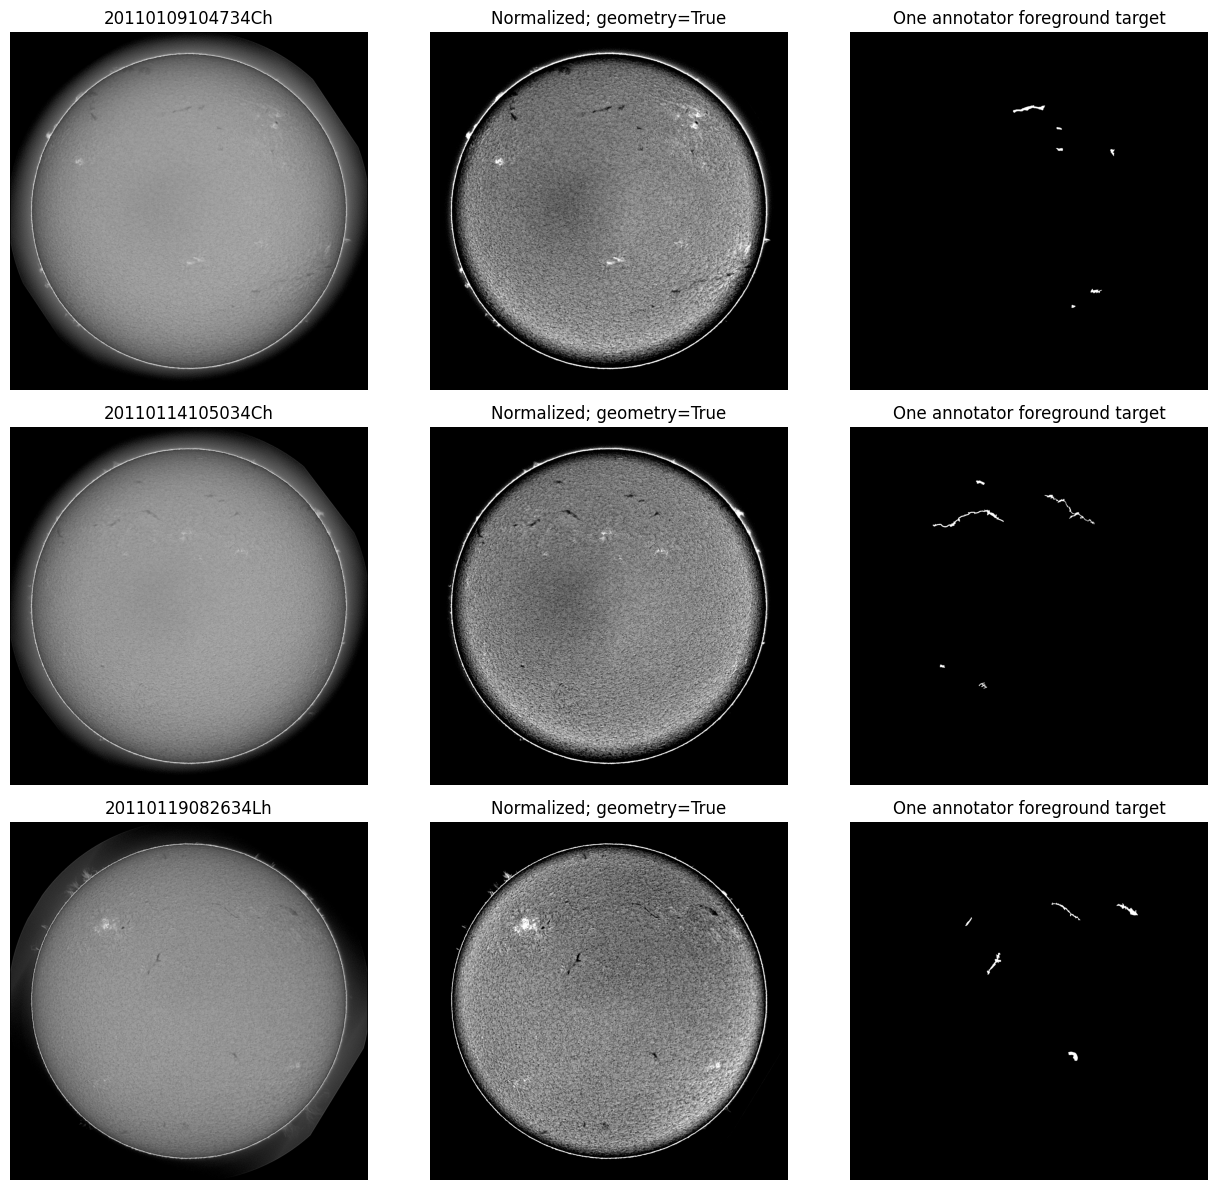

In [16]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

examples = MANIFEST['splits']['train'][:3]
fig, axes = plt.subplots(len(examples), 3, figsize=(13, 4 * len(examples)), squeeze=False)
for row, source in zip(axes, examples):
    row[0].imshow(read_gray(source['image']), cmap='gray')
    row[0].set_title(source['stem'])
    row[1].imshow(cv2.imread(source['cache'])[:, :, 1], cmap='gray')
    row[1].set_title('Normalized; geometry=' + str(source['photometry']['geometry_ok']))
    packed = cv2.imread(source['views'][0]['target'], 0)
    row[2].imshow((packed & 1) > 0, cmap='gray')
    row[2].set_title('One annotator foreground target')
    for axis in row:
        axis.axis('off')
fig.tight_layout()
fig.savefig(RUN / 'preprocessing_preview.png', dpi=130)
plt.show()

## Train detector and native mask models

Each training job launches an importable script with `torchrun`, avoiding notebook
DDP pickling problems. Jobs train sequentially; each uses both GPUs. Mask losses
combine boundary-weighted BCE, foreground Dice and an auxiliary contour loss.
Encoder BN statistics are frozen, decoder normalization uses GroupNorm, and EMA
weights are evaluated. The cosine schedule completes its planned decay.

Full-mode detector validation uses one image and zero additional loader workers;
training uses two loader workers per rank. Generic COCO/ImageNet initialization
is downloaded, with **no weights trained on external solar-filament labels**.

In [17]:
train_all(CFG, full=False)
print('Selection model checkpoints:', model_paths(CFG, full=False))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Launching: /usr/bin/python3 -m torch.distributed.run --standalone --nnodes=1 --nproc_per_node=2 /kaggle/working/filament_gpu_worker.py --config /kaggle/working/kaggle_native_hybrid_v1_8d27489d35/config.json --task detector
New https://pypi.org/project/ultralytics/8.4.200 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
Overriding model.yaml nc=80 with nc=1
Transferred 643/649 items from pretrained weights
Freezing layer 'model.23.dfl.conv.weight'
AMP: running Automatic Mixed Precision (AMP) checks...
AMP: checks passed ✅
train: Fa

/usr/local/lib/python3.13/dist-packages/torch/distributed/c10d_logger.py:83: UserWarning: barrier(): using the device under current context. You can specify `device_id` in `init_process_group` to mute this warning.
  return func(*args, **kwargs)


Dense member 0, rank 1/2: cuda:1, 532 sources, native 512 crops, 288 microbatches/epoch, 2 loader workers
Dense member 0, rank 0/2: cuda:0, 532 sources, native 512 crops, 288 microbatches/epoch, 2 loader workers
{"rank": 1, "world_size": 2, "gpu": "cuda:1", "gpu_name": "Tesla T4", "observed_batch": 2, "native_crop": [512, 512], "loader_workers": 2, "total_loader_workers": 4}
{"rank": 0, "world_size": 2, "gpu": "cuda:0", "gpu_name": "Tesla T4", "observed_batch": 2, "native_crop": [512, 512], "loader_workers": 2, "total_loader_workers": 4}
Dense 0 rank 0: epoch 1/32, step 32/288, loss 0.7381, lr 0.000033
Dense 0 rank 1: epoch 1/32, step 32/288, loss 0.7395, lr 0.000033
Dense 0 rank 0: epoch 1/32, step 64/288, loss 0.7190, lr 0.000067
Dense 0 rank 1: epoch 1/32, step 64/288, loss 0.7207, lr 0.000067
Dense 0 rank 1: epoch 1/32, step 96/288, loss 0.7023, lr 0.000100
Dense 0 rank 0: epoch 1/32, step 96/288, loss 0.7020, lr 0.000100
Dense 0 rank 1: epoch 1/32, step 128/288, loss 0.6852, lr 0.

Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.
/usr/local/lib/python3.13/dist-packages/torch/distributed/c10d_logger.py:83: UserWarning: barrier(): using the device under current context. You can specify `device_id` in `init_process_group` to mute this warning.
  return func(*args, **kwargs)
Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


Dense member 1, rank 1/2: cuda:1, 532 sources, native 768 crops, 288 microbatches/epoch, 2 loader workers
Dense member 1, rank 0/2: cuda:0, 532 sources, native 768 crops, 288 microbatches/epoch, 2 loader workers
{"rank": 1, "world_size": 2, "gpu": "cuda:1", "gpu_name": "Tesla T4", "observed_batch": 2, "native_crop": [768, 768], "loader_workers": 2, "total_loader_workers": 4}
{"rank": 0, "world_size": 2, "gpu": "cuda:0", "gpu_name": "Tesla T4", "observed_batch": 2, "native_crop": [768, 768], "loader_workers": 2, "total_loader_workers": 4}
Dense 1 rank 1: epoch 1/32, step 32/288, loss 0.9839, lr 0.000033
Dense 1 rank 0: epoch 1/32, step 32/288, loss 0.9854, lr 0.000033
Dense 1 rank 0: epoch 1/32, step 64/288, loss 0.9722, lr 0.000067
Dense 1 rank 1: epoch 1/32, step 64/288, loss 0.9727, lr 0.000067
Dense 1 rank 0: epoch 1/32, step 96/288, loss 0.9544, lr 0.000100
Dense 1 rank 1: epoch 1/32, step 96/288, loss 0.9552, lr 0.000100
Dense 1 rank 0: epoch 1/32, step 128/288, loss 0.9326, lr 0.

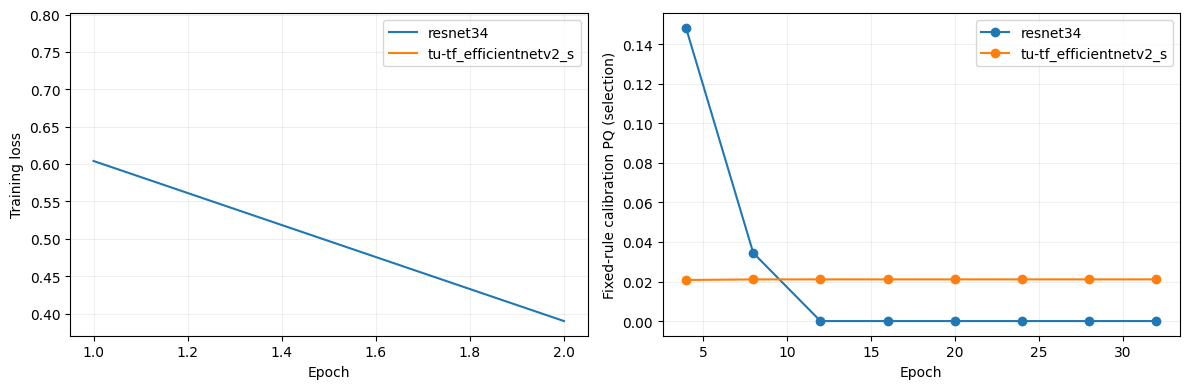

In [18]:
import pandas as pd
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for member in range(len(CFG['dense_models'])):
    history = pd.read_json(RUN / 'selection_models' / f'dense_{member}' / 'history.jsonl', lines=True)
    label = CFG['dense_models'][member]['encoder']
    axes[0].plot(history.epoch, history.loss, label=label)
    checked = history.dropna(subset=['fixed_rule_calibration_PQ'])
    axes[1].plot(checked.epoch, checked.fixed_rule_calibration_PQ, marker='o', label=label)
axes[0].set(xlabel='Epoch', ylabel='Training loss')
axes[1].set(xlabel='Epoch', ylabel='Fixed-rule calibration PQ (selection)')
for axis in axes:
    axis.legend()
    axis.grid(alpha=.2)
fig.tight_layout()
fig.savefig(RUN / 'training_history.png', dpi=150)
plt.show()

## Calibrate on dates excluded from training

Inference averages four exact flip views from both U-Nets, with Hann-weighted tile
blending. YOLO boxes are fused across views while retaining separate proposals.
Masks from proposals can retain disconnected pieces as one instance. Every final
pixel belongs to at most one mask. Plain semantic components are a competing
pipeline and an optional detector-miss recovery source.

Candidate generation retains at most 512 semantic components per threshold, ranked
by mean probability when that guard is reached. This bounds work for an untrained
or failing model while retaining small confident components. Normal filament counts
are far below this guard; `max_dense_candidates` is configurable.

The quality model uses image-derived contrast, shape, uncertainty, contour strength,
detector confidence and TTA support. It has no filename/site/label metadata at
inference. Calibration-only targets are the mean credited IoU over annotation
views. Date-grouped crossfitting prevents scoring each calibration candidate with
a quality model fitted on that date. The report will use a model fitted on all
calibration dates and the frozen recipe.

In [19]:
CALIBRATION_MAPS = predict_part(CFG, 'calibration', full=False)
CALIBRATION_CANDIDATES = build_candidate_cache(CFG, 'calibration', CALIBRATION_MAPS)
RECIPE = calibrate(CFG, CALIBRATION_CANDIDATES)
display(pd.DataFrame(load_json(RUN / 'calibration_grid.json')).head(12))

/kaggle/working/filament_gpu_worker.py:915: RuntimeWarning: invalid value encountered in cast
  np.savez_compressed(f, prob=np.rint(np.clip(probability, 0, 1) * 255).astype(np.uint8), boxes=boxes)
/kaggle/working/filament_gpu_worker.py:915: RuntimeWarning: invalid value encountered in cast
  np.savez_compressed(f, prob=np.rint(np.clip(probability, 0, 1) * 255).astype(np.uint8), boxes=boxes)


Prediction GPU 0: calibration 1/41 20110123174914Mh, 5 proposals
Prediction GPU 1: calibration 1/41 20110128174814Mh, 12 proposals
Prediction GPU 1: calibration 2/41 20110312082634Lh, 22 proposals
Prediction GPU 0: calibration 2/41 20110215083814Th, 11 proposals
Prediction GPU 1: calibration 3/41 20110601063134Lh, 23 proposals
Prediction GPU 0: calibration 3/41 20110425063154Uh, 22 proposals
Prediction GPU 1: calibration 4/41 20110823120334Ch, 7 proposals
Prediction GPU 0: calibration 4/41 20110617063134Lh, 18 proposals
Prediction GPU 1: calibration 5/41 20111029063154Uh, 28 proposals
Prediction GPU 0: calibration 5/41 20111018063134Lh, 11 proposals
Prediction GPU 1: calibration 6/41 20120215153654Bh, 37 proposals
Prediction GPU 0: calibration 6/41 20120113104834Ch, 26 proposals
Prediction GPU 1: calibration 7/41 20120223152054Bh, 14 proposals
Prediction GPU 0: calibration 7/41 20120223063154Uh, 14 proposals
Prediction GPU 1: calibration 8/41 20120703070814Th, 31 proposals
Prediction G

,set,quality,cutoff,min_area,PQ,SQ,RQ,TP,FP,FN,sum_IoU,physical_predictions
0,hybrid_adaptive,True,0.15,50,0.011172,0.629332,0.017751,9,6,990,5.663985,11
1,hybrid_adaptive,True,0.15,150,0.011172,0.629332,0.017751,9,6,990,5.663985,11
2,hybrid_0.5,True,0.15,50,0.010800,0.607828,0.017769,9,5,990,5.470452,10
3,hybrid_0.5,True,0.15,150,0.010800,0.607828,0.017769,9,5,990,5.470452,10
4,dense_0.65,True,0.15,50,0.010428,0.660249,0.015795,8,6,991,5.281988,10
5,dense_0.65,True,0.15,150,0.010428,0.660249,0.015795,8,6,991,5.281988,10
6,hybrid_0.65,True,0.15,50,0.010388,0.657678,0.015795,8,6,991,5.261421,10
7,hybrid_0.65,True,0.15,150,0.010388,0.657678,0.015795,8,6,991,5.261421,10
8,dense_adaptive,True,0.15,50,0.009987,0.634186,0.015748,8,9,991,5.073487,11
9,dense_adaptive,True,0.15,150,0.009987,0.634186,0.015748,8,9,991,5.073487,11


## Evaluate the frozen pipeline once on the report partition

The implementation follows the organizer's strict **IoU > 0.5** overlap rule and
pools counts across **individual annotator-image records**. It does not score a
merged union or average per-image PQ. Keep this result as the honest pre-refit
estimate. Do not tune repeatedly against this set or assume it equals public PQ.

/kaggle/working/filament_gpu_worker.py:915: RuntimeWarning: invalid value encountered in cast
  np.savez_compressed(f, prob=np.rint(np.clip(probability, 0, 1) * 255).astype(np.uint8), boxes=boxes)
/kaggle/working/filament_gpu_worker.py:915: RuntimeWarning: invalid value encountered in cast
  np.savez_compressed(f, prob=np.rint(np.clip(probability, 0, 1) * 255).astype(np.uint8), boxes=boxes)


Prediction GPU 1: report 1/46 20110326170914Mh, 7 proposals
Prediction GPU 0: report 1/47 20110221173814Mh, 4 proposals
Prediction GPU 1: report 2/46 20110526122534Ch, 28 proposals
Prediction GPU 0: report 2/47 20110509121334Ch, 22 proposals
Prediction GPU 1: report 3/46 20110727063234Lh, 12 proposals
Prediction GPU 0: report 3/47 20110711071214Th, 25 proposals
Prediction GPU 1: report 4/46 20110824141054Bh, 20 proposals
Prediction GPU 0: report 4/47 20110815140454Bh, 20 proposals
Prediction GPU 1: report 5/46 20111116063134Lh, 33 proposals
Prediction GPU 0: report 5/47 20111009110234Ch, 22 proposals
Prediction GPU 0: report 6/47 20120225172914Mh, 13 proposals
Prediction GPU 1: report 6/46 20120323144054Bh, 17 proposals
Prediction GPU 0: report 7/47 20120331142954Bh, 30 proposals
Prediction GPU 1: report 7/46 20120424072414Th, 28 proposals
Prediction GPU 0: report 8/47 20120424120134Ch, 23 proposals
Prediction GPU 1: report 8/46 20120712123634Ch, 25 proposals
Prediction GPU 1: report 9

,PQ,SQ,RQ,TP,FP,FN,sum_IoU,physical_images,cohorts,note
0,0.003451,0.632124,0.00546,3,17,1076,1.896373,93,"{'disk_fit': {'PQ': 0.0013598467773811888, 'SQ...",Independent report; frozen recipe and calibrat...


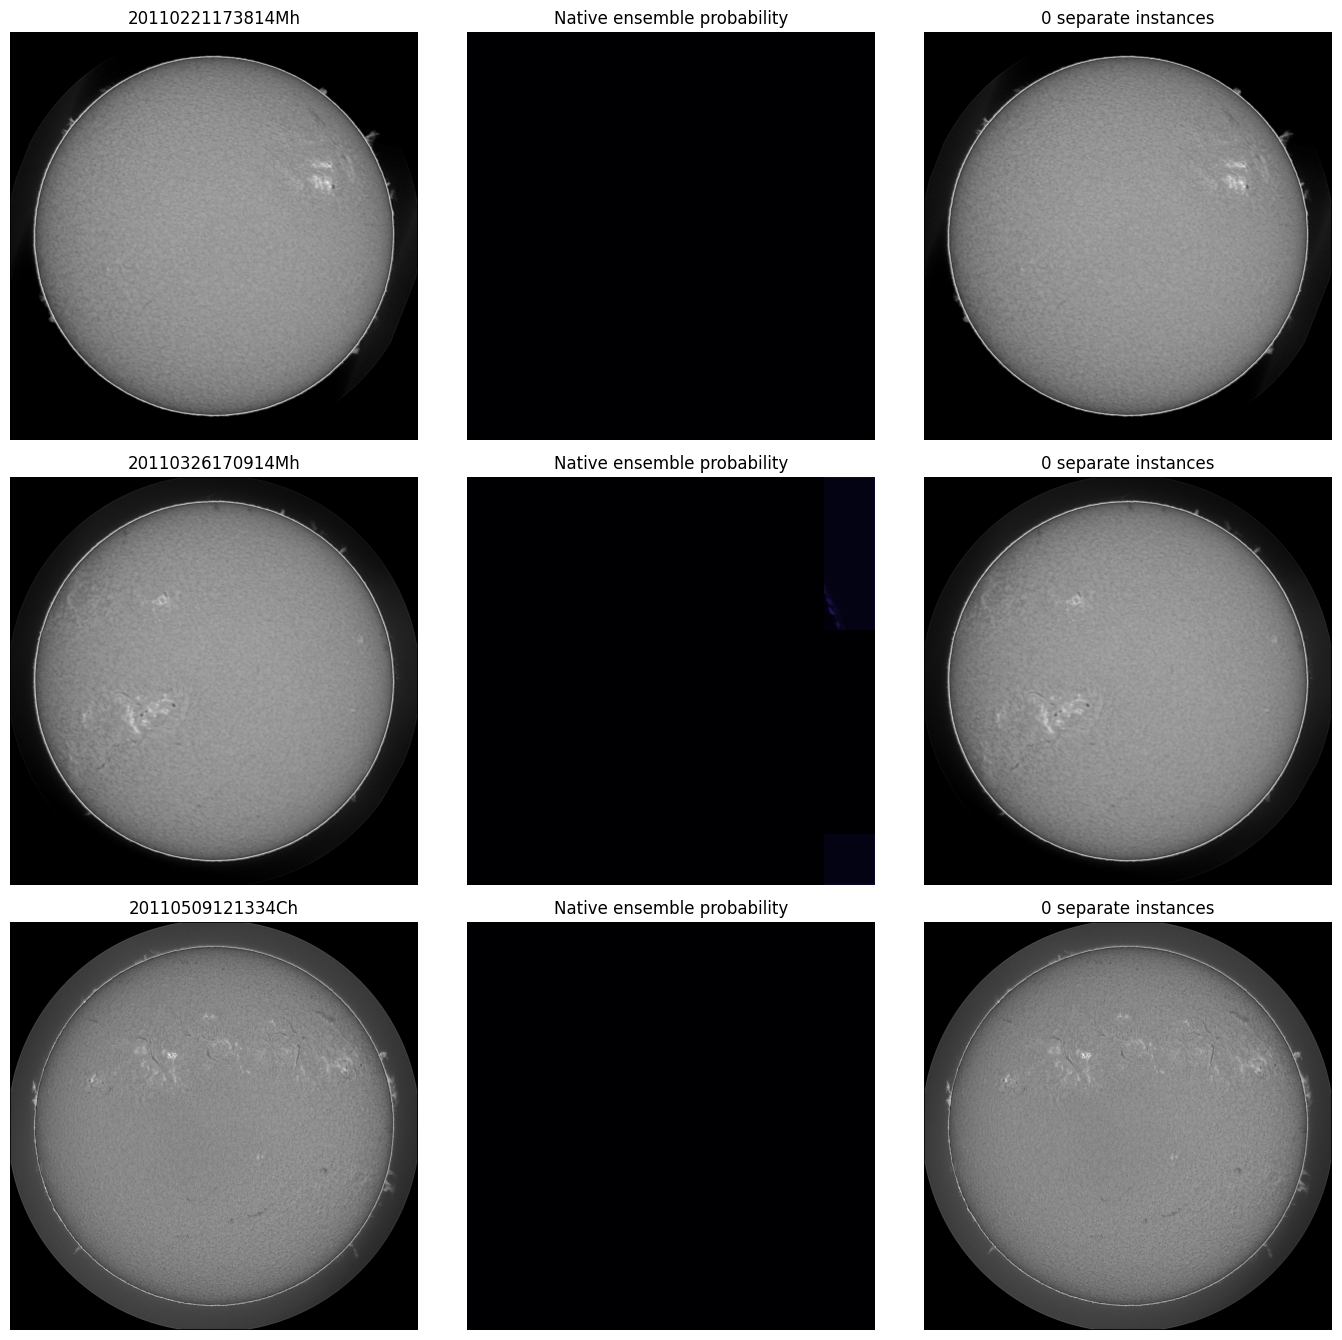

In [20]:
REPORT_MAPS = predict_part(CFG, 'report', full=False)
REPORT_CANDIDATES = build_candidate_cache(CFG, 'report', REPORT_MAPS)
REPORT = evaluate_report(CFG, REPORT_CANDIDATES, RECIPE)
display(pd.DataFrame([REPORT]))
preview(CFG, 'report', REPORT_CANDIDATES, RECIPE)
plt.show()

## Frozen full-data refit and submission.csv

When enabled, retrain on train + calibration + report annotations using the epoch
counts already selected during the earlier stage. Keep the quality model and
postprocessing frozen. This uses all legal training data but has no remaining
independent local score; the saved report belongs to the previous models.
If semantic-only masks win calibration, skip the unused detector's full-data retrain.

The final CSV uses `filament_id,segmentation_rle`, native 2048² column-major COCO
compressed RLE counts, original filename stems and one-based instance counters.
Empty images are logged without invented masks. The exporter checks identifiers,
all test-image coverage, mask dimensions, RLE round trips and pixel non-overlap.

In [21]:
if CFG['refit_full']:
    train_all(CFG, full=True)
TEST_MAPS = predict_part(CFG, 'test', full=CFG['refit_full'])
TEST_CANDIDATES = build_candidate_cache(CFG, 'test', TEST_MAPS)
SUBMISSION = export_submission(CFG, TEST_CANDIDATES, RECIPE)
print('Submission:', SUBMISSION)
display(pd.read_csv(SUBMISSION).head())
display(load_json(RUN / 'submission_audit.json'))

Launching: /usr/bin/python3 -m torch.distributed.run --standalone --nnodes=1 --nproc_per_node=2 /kaggle/working/filament_gpu_worker.py --config /kaggle/working/kaggle_native_hybrid_v1_8d27489d35/config.json --task detector --full
New https://pypi.org/project/ultralytics/8.4.201 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
Overriding model.yaml nc=80 with nc=1
Transferred 643/649 items from pretrained weights
Freezing layer 'model.23.dfl.conv.weight'
AMP: running Automatic Mixed Precision (AMP) checks...
AMP: checks passed ✅
train: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2460.8±1366.0 MB/s, size: 4696.3 KB)
train: Scanning /kaggle/working/kaggle_native_hybrid_v1_8d27489d35/detector_data/labels/calibration... 1154 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1154/1154 27.3it/s 42.3s
train: New cache cre

/usr/local/lib/python3.13/dist-packages/torch/distributed/c10d_logger.py:83: UserWarning: barrier(): using the device under current context. You can specify `device_id` in `init_process_group` to mute this warning.
  return func(*args, **kwargs)


Dense member 0, rank 1/2: cuda:1, 707 sources, native 512 crops, 383 microbatches/epoch, 2 loader workers
Dense member 0, rank 0/2: cuda:0, 707 sources, native 512 crops, 383 microbatches/epoch, 2 loader workers
{"rank": 0, "world_size": 2, "gpu": "cuda:0", "gpu_name": "Tesla T4", "observed_batch": 2, "native_crop": [512, 512], "loader_workers": 2, "total_loader_workers": 4}
{"rank": 1, "world_size": 2, "gpu": "cuda:1", "gpu_name": "Tesla T4", "observed_batch": 2, "native_crop": [512, 512], "loader_workers": 2, "total_loader_workers": 4}
Dense 0 rank 1: epoch 1/4, step 32/383, loss 0.7428, lr 0.000025
Dense 0 rank 0: epoch 1/4, step 32/383, loss 0.7412, lr 0.000025
Dense 0 rank 1: epoch 1/4, step 64/383, loss 0.7248, lr 0.000050
Dense 0 rank 0: epoch 1/4, step 64/383, loss 0.7251, lr 0.000050
Dense 0 rank 1: epoch 1/4, step 96/383, loss 0.7087, lr 0.000075
Dense 0 rank 0: epoch 1/4, step 96/383, loss 0.7089, lr 0.000075
Dense 0 rank 1: epoch 1/4, step 128/383, loss 0.6934, lr 0.000099


Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.
/usr/local/lib/python3.13/dist-packages/torch/distributed/c10d_logger.py:83: UserWarning: barrier(): using the device under current context. You can specify `device_id` in `init_process_group` to mute this warning.
  return func(*args, **kwargs)
Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


Dense member 1, rank 1/2: cuda:1, 707 sources, native 768 crops, 383 microbatches/epoch, 2 loader workers
Dense member 1, rank 0/2: cuda:0, 707 sources, native 768 crops, 383 microbatches/epoch, 2 loader workers
{"rank": 0, "world_size": 2, "gpu": "cuda:0", "gpu_name": "Tesla T4", "observed_batch": 2, "native_crop": [768, 768], "loader_workers": 2, "total_loader_workers": 4}
{"rank": 1, "world_size": 2, "gpu": "cuda:1", "gpu_name": "Tesla T4", "observed_batch": 2, "native_crop": [768, 768], "loader_workers": 2, "total_loader_workers": 4}
Dense 1 rank 0: epoch 1/12, step 32/383, loss 0.9845, lr 0.000025
Dense 1 rank 1: epoch 1/12, step 32/383, loss 0.9848, lr 0.000025
Dense 1 rank 0: epoch 1/12, step 64/383, loss 0.9760, lr 0.000050
Dense 1 rank 1: epoch 1/12, step 64/383, loss 0.9760, lr 0.000050
Dense 1 rank 0: epoch 1/12, step 96/383, loss 0.9625, lr 0.000075
Dense 1 rank 1: epoch 1/12, step 96/383, loss 0.9621, lr 0.000075
Dense 1 rank 0: epoch 1/12, step 128/383, loss 0.9452, lr 0.

/kaggle/working/filament_gpu_worker.py:915: RuntimeWarning: invalid value encountered in cast
  np.savez_compressed(f, prob=np.rint(np.clip(probability, 0, 1) * 255).astype(np.uint8), boxes=boxes)
/kaggle/working/filament_gpu_worker.py:915: RuntimeWarning: invalid value encountered in cast
  np.savez_compressed(f, prob=np.rint(np.clip(probability, 0, 1) * 255).astype(np.uint8), boxes=boxes)


Prediction GPU 1: test 1/90 20110130110334Ch, 2 proposals
Prediction GPU 0: test 1/90 20110120105534Ch, 4 proposals
Prediction GPU 1: test 2/90 20110329082654Uh, 23 proposals
Prediction GPU 0: test 2/90 20110214175414Mh, 10 proposals
Prediction GPU 1: test 3/90 20110424064534Lh, 21 proposals
Prediction GPU 0: test 3/90 20110408083214Th, 23 proposals
Prediction GPU 1: test 4/90 20110529063154Uh, 19 proposals
Prediction GPU 0: test 4/90 20110429120534Ch, 28 proposals
Prediction GPU 1: test 5/90 20110603123034Ch, 20 proposals
Prediction GPU 0: test 5/90 20110531070514Th, 18 proposals
Prediction GPU 1: test 6/90 20110811121534Ch, 34 proposals
Prediction GPU 0: test 6/90 20110706164014Mh, 6 proposals
Prediction GPU 0: test 7/90 20110819131834Ch, 16 proposals
Prediction GPU 1: test 7/90 20110827141254Bh, 12 proposals
Prediction GPU 1: test 8/90 20111015063134Lh, 32 proposals
Prediction GPU 0: test 8/90 20110912142254Bh, 26 proposals
Prediction GPU 1: test 9/90 20111114063134Lh, 30 proposals


,filament_id,segmentation_rle
0,20110130110334Ch_1,fb^b01oo12N1O2N001O01O1O10O100O1O001O00001O000...
1,20110130110334Ch_2,^Rm[33lo12N2O0O2O0000000O1O1N110O001O1O10O10O1...
2,20180507140210Th_1,koQf11no1100O2O00000000000000000000000O1000000...
3,20180507140210Th_2,ioWP24ko11O2O000000000000000000000000000000000...
4,20181030230030Lh_1,[gm]14ko12M3N2N2N3bPNAWo1f0N2N10O02O01O2O01N8I...


{'file': '/kaggle/working/kaggle_native_hybrid_v1_8d27489d35/submission.csv',
 'sha256': '624ae7b947eb6f14531c30ae860068bf5dbf4db129949ab86d214c17bc0c00ac',
 'native_shape': [2048, 2048],
 'images': 180,
 'masks': 6,
 'zero_prediction_images': 176,
 'per_image': [{'image': '20110120105534Ch.jpeg',
   'predictions': 0,
   'geometry_ok': True},
  {'image': '20110130110334Ch.jpeg', 'predictions': 2, 'geometry_ok': True},
  {'image': '20110214175414Mh.jpeg', 'predictions': 0, 'geometry_ok': False},
  {'image': '20110329082654Uh.jpeg', 'predictions': 0, 'geometry_ok': True},
  {'image': '20110408083214Th.jpeg', 'predictions': 0, 'geometry_ok': True},
  {'image': '20110424064534Lh.jpeg', 'predictions': 0, 'geometry_ok': True},
  {'image': '20110429120534Ch.jpeg', 'predictions': 0, 'geometry_ok': True},
  {'image': '20110529063154Uh.jpeg', 'predictions': 0, 'geometry_ok': True},
  {'image': '20110531070514Th.jpeg', 'predictions': 0, 'geometry_ok': True},
  {'image': '20110603123034Ch.jpeg', '

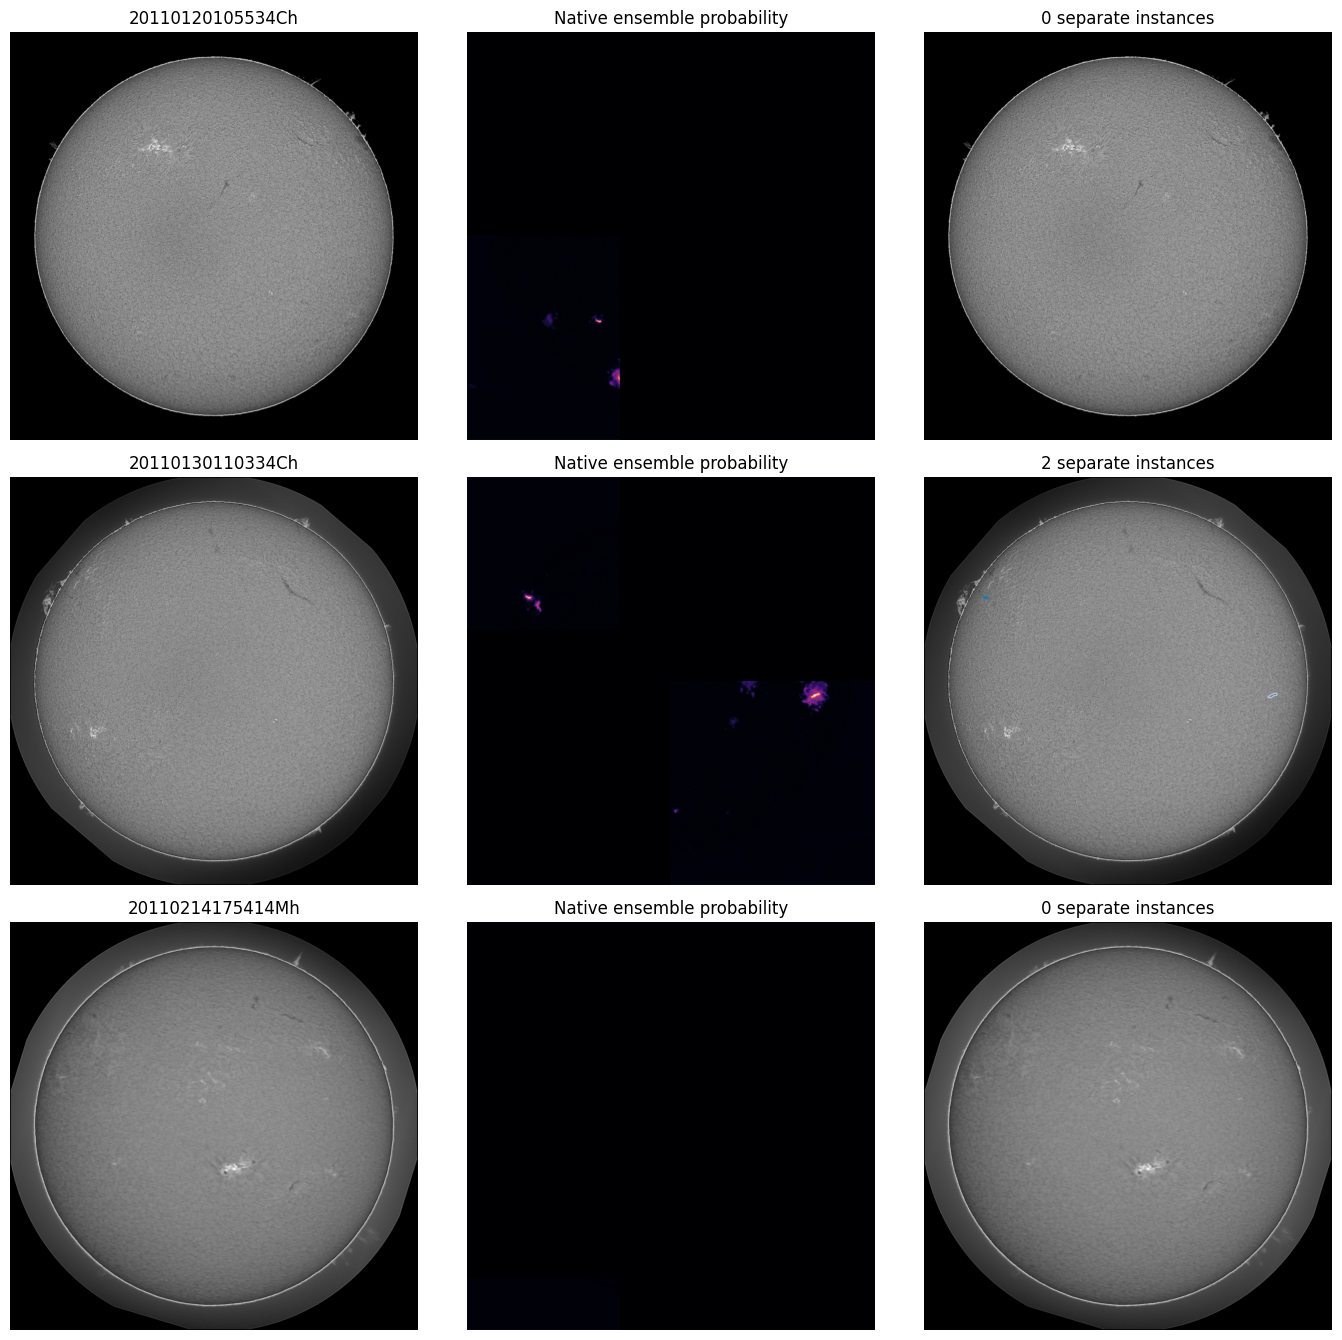

/kaggle/working/kaggle_native_hybrid_v1_8d27489d35/submission.csv

Full runs also copy submission.csv to: /kaggle/working/submission.csv
Review report_metrics.json, submission_audit.json and the previews before uploading.


In [22]:
preview(CFG, 'test', TEST_CANDIDATES, RECIPE)
plt.show()
from IPython.display import FileLink, display
display(FileLink(str(SUBMISSION)))
print('Full runs also copy submission.csv to:', Path(CFG['output_root']).resolve() / 'submission.csv')
print('Review report_metrics.json, submission_audit.json and the previews before uploading.')

## Outputs and validation

The completed full run writes **`/kaggle/working/submission.csv`**. Find it in
Kaggle's Output/Files panel. Its run folder also contains calibration choices,
held-out report metrics, training curves, model weights, prediction previews and
`submission_audit.json`. The exporter checks all 180 test images, native 2048 masks,
unique IDs, compressed COCO RLE round trips and non-overlapping instances.

Training uses the supplied competition annotations. External solar-filament labels
and test annotations are excluded. Generic COCO/ImageNet initialization is used.
The report is evaluated before the optional full-data refit, so its score belongs
to the earlier models. No score above 0.50 is claimed for this notebook.

Method references: [competition evaluation](https://www.kaggle.com/competitions/filament-segmentation-2026/overview/important-dates),
[organizer scoring](https://www.kaggle.com/code/azimahmadzadeh/self-evaluation-notebook),
[detector/native-mask hybrid](https://github.com/ameyypawar/filament-seg),
[detection/refinement experiments](https://github.com/HeShen-1/filament-segmentation-2026).
Dependency licenses, including Ultralytics AGPL-3.0, continue to apply.